# Notebook for analysis of bulk RNAseq data in BULLKpy
## Notebook 2. Clustering, signatures, statistics and general exploration
@mmm, November 4, 2026

<div style="font-size: 24px; line-height: 1.1">
Notebook Menu

<div style="font-size: 18px; line-height: 1.4">
<a href="#imports">1. Imports and settings</a><br>
<a href="#loads">2. Load the .h5ad object</a><br>
<a href="#clusters">3. Clustering and groups</a><br>
<a href="#genes">4. Genes and Gene Signatures</a><br>
<a href="#exploration">5. Data Exploration</a><br>
<a href="#correlations">6. Associations & Correlations</a><br>
<a href="#plots">7. Additional Plots</a><br>

# 1. Imports and settings
<a id="imports"></a>

## 1.1. Modules and Settings

In [1]:
import os
import re
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import seaborn as sns

from datetime import datetime

import anndata as ad
import bullkpy as bk

In [2]:
import sys
sys.version
print("Python:", sys.version, "Numpy:", np.__version__, "Pandas:", pd.__version__, "Matplotlib:", mpl.__version__, "Seaborn:", sns.__version__, 
      "AnnData:", ad.__version__)

Python: 3.12.13 (main, May 10 2026, 19:20:41) [Clang 22.1.3 ] Numpy: 2.4.6 Pandas: 3.0.5 Matplotlib: 3.11.1 Seaborn: 0.13.2 AnnData: 0.13.2


In [3]:
bk.settings.verbosity = 3
bk.settings.plot_theme = "paper"      # "default" | "paper" | "talk"
bk.settings.plot_palette = "Set1"
bk.settings.plot_fontsize = 10        # optional
bk.settings.plot_dpi = 200
bk.settings.save_dpi = 300

# every plot calls set_style() internally, or you can call once:
bk.pl.set_style()
pal = sns.color_palette("husl", n_colors=35)       # palette for large categories
bk.settings.set_palette_for("Project_ID", where="obs", palette="husl")

import warnings
warnings.filterwarnings("ignore", category=FutureWarning, module="lifelines")

Change to paths with your files:

In [4]:
# Point these at your own folder structure.

DATA = "../data/"
DATA_EXTERNAL = "../data/external/"
DATA_H5AD = '../data/h5ad/'

RESULTS = "../results/"
FIGURES = "../results/figs/"
TABLES = "../results/tables/"
GSEA = "../results/gsea/"

import os
for _p in (DATA, DATA_EXTERNAL):
    if not os.path.isdir(_p):
        print(f"WARNING: {_p} not found - update DATA above before running section 2.")

# Single source of truth for the objects this notebook builds, so every save and
# reload below refers to the same file.

H5AD      = DATA_H5AD + "TCGA_lung.h5ad"


# 2. Load data into AnnData and BULLKpy object
<a id="loads"></a>

In [5]:
## Load the .h5ad object with all modifications from the previous notebook     
#This is the starting point for this notebook.

adata = ad.read_h5ad(H5AD)
adata 

AnnData object with n_obs × n_vars = 1108 × 31891
    obs: 'Sample_ID', 'Patient_ID', 'Project_ID', 'gender', 'race', 'ajcc_pathologic_tumor_stage', 'histological_type', 'initial_pathologic_dx_year', 'birth_days_to', 'vital_status', 'tumor_status', 'last_contact_days_to', 'death_days_to', 'new_tumor_event_type', 'new_tumor_event_dx_days_to', 'treatment_outcome_first_course', 'OS', 'OS.time', 'DSS', 'DSS.time', 'DFI', 'DFI.time', 'PFI', 'PFI.time', 'Subtype_mRNA', 'Subtype_DNAmeth', 'Subtype_Integrative', 'Subtype_Selected', 'sample_type_id', 'sample_type', '_primary_disease', 'Subtype_Immune_Model_Based', 'ICS5_score', 'LIexpression_score', 'Chemokine12_score', 'NHI_5gene_score', 'CD68', 'CD8A', 'PD1_data', 'PDL1_data', 'PD1_PDL1_score', 'CTLA4_data', 'Bcell_mg_IGJ', 'Bcell_receptors_score', 'STAT1_score', 'CSF1_response', 'TcClassII_score', 'IL12_score_21050467', 'IL4_score_21050467', 'IL2_score_21050467', 'IL13_score_21050467', 'IFNG_score_21050467', 'TGFB_score_21050467', 'TREM1_dat

# 3. Clustering and define groups <a id="clusters"></a> 

Basic procedure: PCA → 2) neighbors graph on PCs → 3) Leiden (scan resolution)   
- Use `method=leiden` for computational of clusters. `resolution`: Higher resolution → more clusters // Lower resolution → fewer clusters. Leiden requires a graph, so run after `bk.tl.neighbors` (already computed for UMAP)  
- Use K-means when you want direct control over the number of clusters or a quick baseline.   
Try Leiden; if not installed it will fallback to kmeans automatically  


## 3.1. Leiden  
For complex structure and unknown number of clusters

In [6]:
# Initial test if true groups already known. Scan many Leiden resolutions
df = bk.tl.leiden_resolution_scan(
    adata,
    true_key="Project_ID",                                          # Biological true groups                    
    resolutions=[0.4, 0.6, 0.8, 1.0, 1.5],
    base_key="leiden",
    use_rep="X_pca",
    n_pcs=20,
    n_neighbors=15,
)
df

,resolution,key,n_clusters,ARI,NMI,cramers_v,n_used,n_missing
0,0.4,leiden_0.4,4,0.492363,0.453994,0.851050,1108,0
1,0.6,leiden_0.6,5,0.332944,0.397828,0.848475,1108,0
2,0.8,leiden_0.8,6,0.291874,0.382177,0.853867,1108,0
3,1.0,leiden_1,8,0.243934,0.356221,0.855800,1108,0
4,1.5,leiden_1.5,14,0.140968,0.297496,0.855703,1108,0


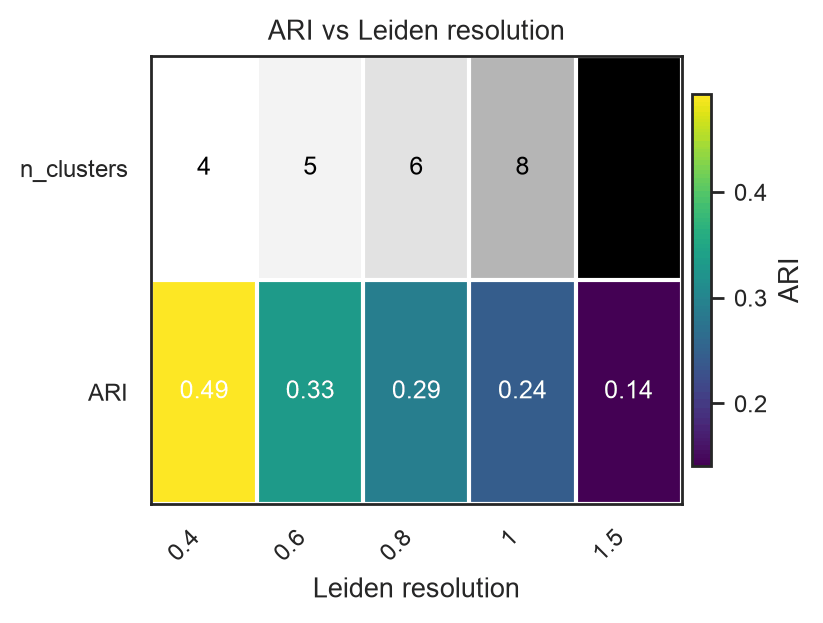

(<Figure size 800x600 with 2 Axes>,
 <Axes: title={'center': 'ARI vs Leiden resolution'}, xlabel='Leiden resolution'>)

In [57]:
# Heatmap of ARI vs resolution in the previous calculations
bk.pl.ari_resolution_heatmap(
    adata,
    df=df,
    metric="ARI",
    show_n_clusters=True,
    figsize=(4,3)
    #save=FIGURES + "ari_vs_resolution.png",      # save optionally
)

In [8]:
# A single calculation with a specific resolution
bk.tl.cluster(adata, method="leiden", key_added="leiden_0.8", resolution=0.8)

In [9]:
# Ensure data are taken as categorical, not numeric. 
# e.g. leiden_0.8
adata.obs["leiden_0.8"] = adata.obs["leiden_0.8"].astype("category")

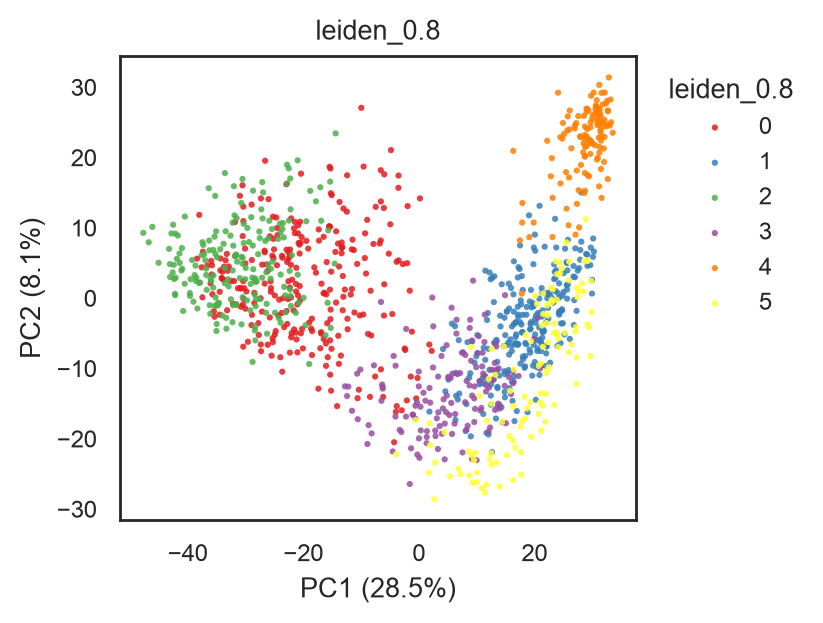

(<Figure size 800x600 with 1 Axes>,
 [<Axes: title={'center': 'leiden_0.8'}, xlabel='PC1 (28.5%)', ylabel='PC2 (8.1%)'>])

In [58]:
bk.pl.pca_scatter(adata, color="leiden_0.8", figsize=(4,3), point_size=5)    
#save=FIGURES + "pca_clusters.png".  #add optionally

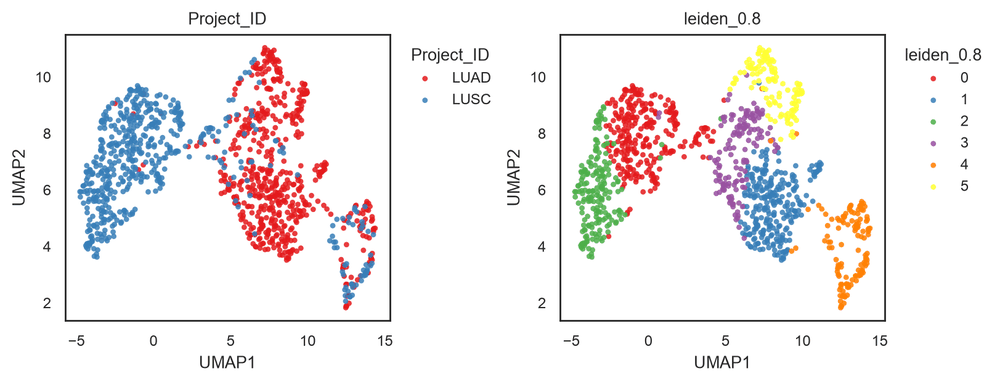

(<Figure size 1600x600 with 2 Axes>,
 array([<Axes: title={'center': 'Project_ID'}, xlabel='UMAP1', ylabel='UMAP2'>,
        <Axes: title={'center': 'leiden_0.8'}, xlabel='UMAP1', ylabel='UMAP2'>],
       dtype=object))

In [60]:
# plot UMAP
bk.pl.umap(adata, color=["Project_ID", "leiden_0.8"], 
           figsize=(4,3),
           point_size=10,    
           save=FIGURES + "UMAP_lein0.8_example.png")

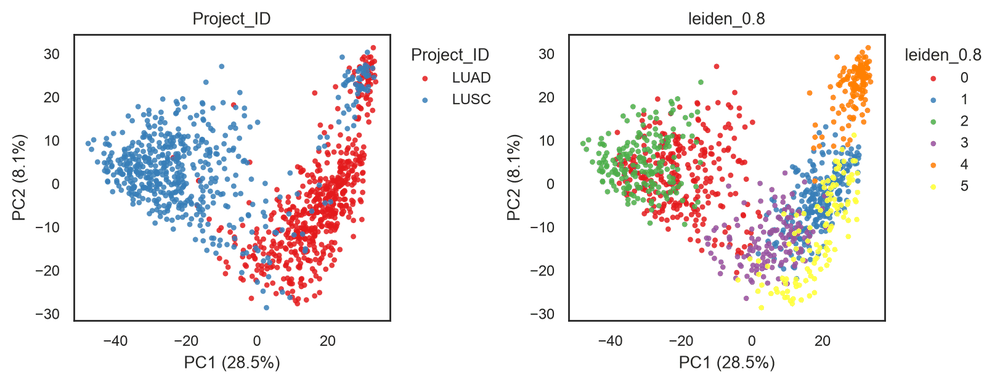

(<Figure size 1600x600 with 2 Axes>,
 array([<Axes: title={'center': 'Project_ID'}, xlabel='PC1 (28.5%)', ylabel='PC2 (8.1%)'>,
        <Axes: title={'center': 'leiden_0.8'}, xlabel='PC1 (28.5%)', ylabel='PC2 (8.1%)'>],
       dtype=object))

In [61]:
# plot PCA
bk.pl.pca_scatter(adata, color=["Project_ID", "leiden_0.8"],  
                  figsize=(4,3),
                  point_size=10,
                  save=FIGURES + "UMAP_lein0.8_example.png")


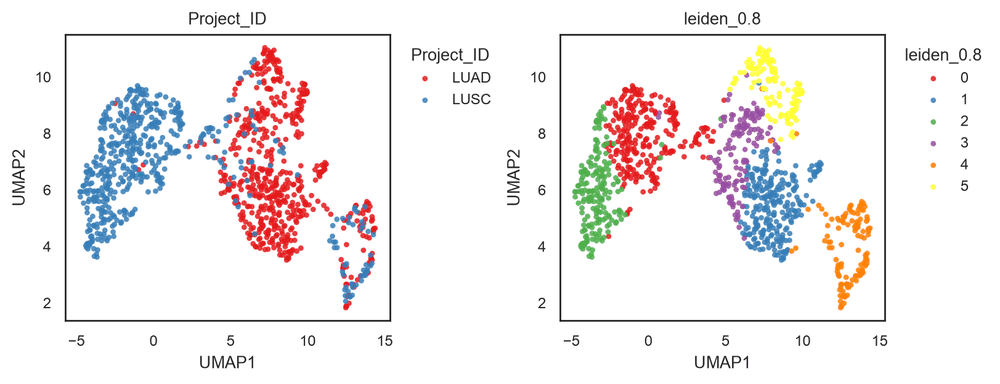

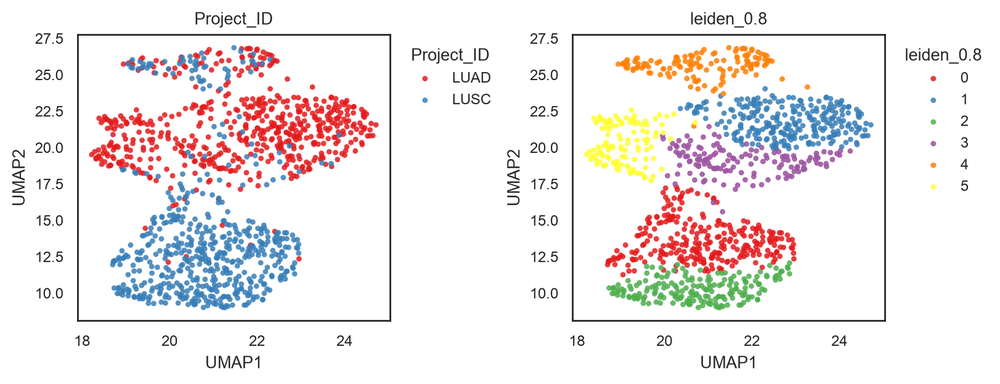

(<Figure size 1600x600 with 2 Axes>,
 array([<Axes: title={'center': 'Project_ID'}, xlabel='UMAP1', ylabel='UMAP2'>,
        <Axes: title={'center': 'leiden_0.8'}, xlabel='UMAP1', ylabel='UMAP2'>],
       dtype=object))

In [62]:
# Compare UMAP and UMAP_Graph
bk.pl.umap(adata, basis="X_umap", color=["Project_ID", "leiden_0.8"], figsize=(4,3), point_size=10)             #save="umap_leiden_standard.png"
bk.pl.umap(adata, basis="X_umap_graph", color=["Project_ID", "leiden_0.8"], figsize=(4,3), point_size=10)      #save="umap_leiden_standard.png"

In [14]:
# Compare results leiden vs. True biological
pd.crosstab(adata.obs["Project_ID"], adata.obs["leiden_0.8"])

leiden_0.8,0,1,2,3,4,5
Project_ID,,,,,,
LUAD,13,257,0,114,72,111
LUSC,260,5,191,27,52,6


In [15]:
# estimate how good is the correlation - Compute ARI - NMI - cramers_v, silhouette
# ARI: from sklearn.metrics import adjusted_rand_score
# NMI: from sklearn.metrics import normalized_mutual_info_score

# Test1. One clustering vs ground truth (plus silhouette on PCA)
#bk.tl.neighbors(adata, n_neighbors=15, n_pcs=20)  # if not done
#bk.tl.cluster(adata, method="leiden", resolution=1.0)

m = bk.tl.cluster_metrics(
    adata,
    true_key="Project_ID",
    cluster_key="leiden_0.8",
    use_rep="X_pca",
    n_pcs=20,
)
m

{'n_used': 1108.0,
 'ari': 0.29187380376966204,
 'nmi': 0.38217672627371124,
 'cramers_v': 0.8516025329437757,
 'silhouette': 0.17060033204004754}

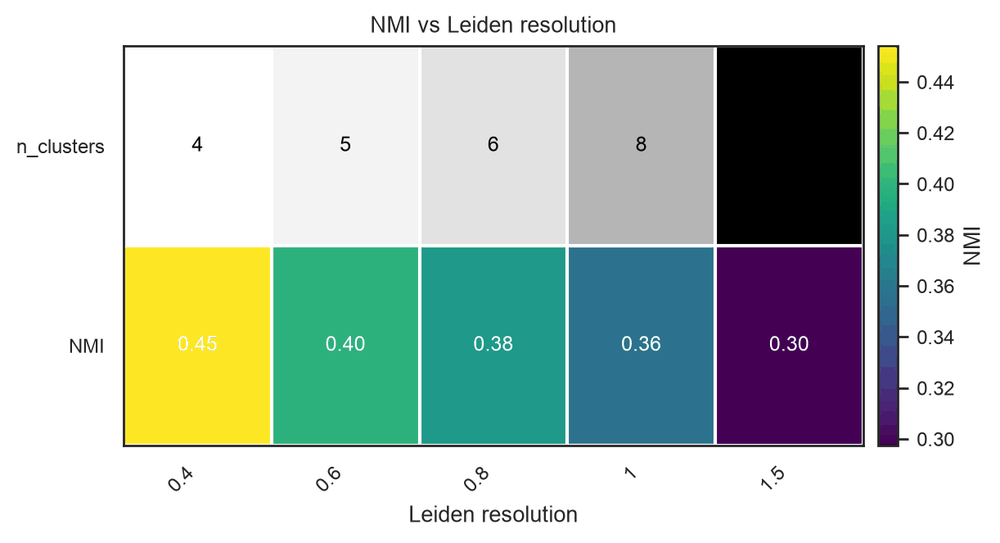

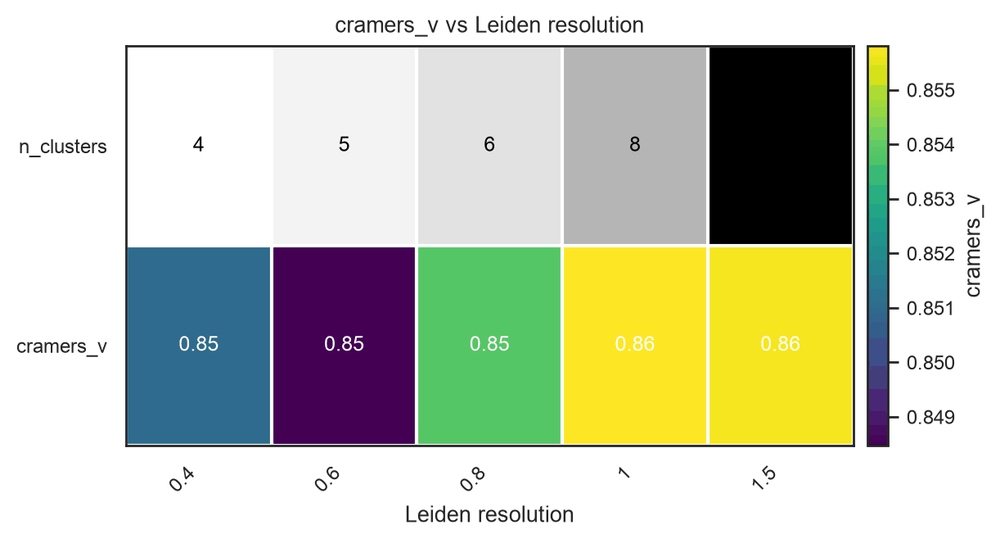

(<Figure size 1200x640 with 2 Axes>,
 <Axes: title={'center': 'cramers_v vs Leiden resolution'}, xlabel='Leiden resolution'>)

In [16]:
# Plot results
bk.pl.ari_resolution_heatmap(adata, df=df, metric="NMI")
bk.pl.ari_resolution_heatmap(adata, df=df, metric="cramers_v")
#bk.pl.ari_resolution_heatmap(adata, df=df, metric="silhouette", vmin=None, vmax=None)

## 5.2. K-means  
Fixed number of clusters

In [17]:
# try several k values
for k in [5, 10, 15, 20, 25]:
    bk.tl.cluster(
        adata,
        method="kmeans",
        n_clusters=k,
        use_rep="X_pca",
        n_pcs=20,
        key_added=f"kmeans_{k}",
    )

In [18]:
# evaluate quantitively
bk.tl.cluster_metrics(
    adata,
    cluster_key="kmeans_25",
    true_key="Project_ID",
)

{'n_used': 1108.0,
 'ari': 0.06998957158724121,
 'nmi': 0.25373446946044603,
 'cramers_v': 0.8488253470244199,
 'silhouette': 0.12902220085216132}

In [19]:
# Calculate for a fixed number of clusters
bk.tl.cluster(
    adata,
    method="kmeans",
    n_clusters=25,
    use_rep="X_pca",
    n_pcs=20,
    key_added="kmeans_25",
    random_state=0,
)

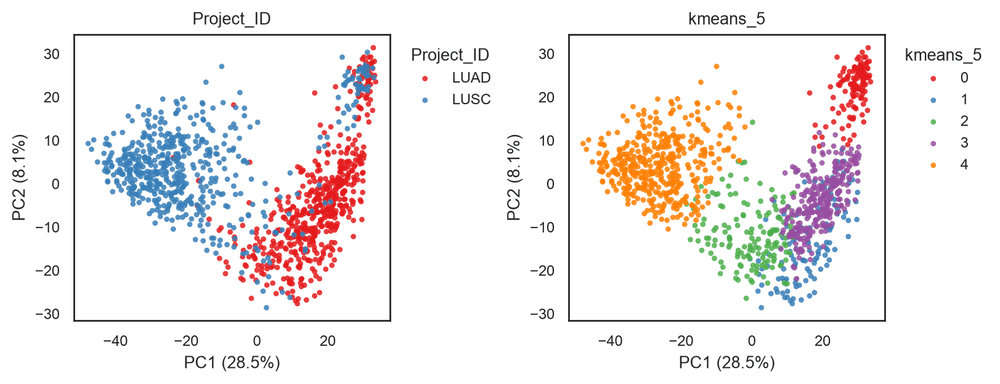

(<Figure size 1600x600 with 2 Axes>,
 array([<Axes: title={'center': 'Project_ID'}, xlabel='PC1 (28.5%)', ylabel='PC2 (8.1%)'>,
        <Axes: title={'center': 'kmeans_5'}, xlabel='PC1 (28.5%)', ylabel='PC2 (8.1%)'>],
       dtype=object))

In [63]:
bk.pl.pca_scatter(adata, color=["Project_ID", "kmeans_5"], figsize=(4,3), point_size=10,
                 save=FIGURES + "PCA_kmeans_5.png")

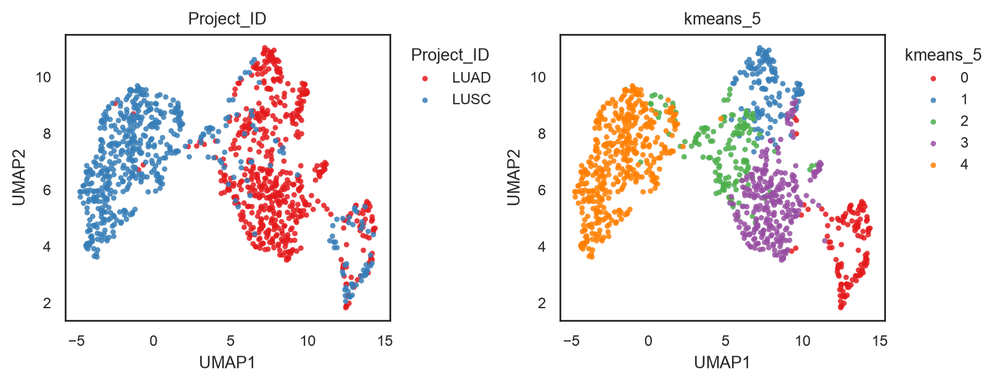

(<Figure size 1600x600 with 2 Axes>,
 array([<Axes: title={'center': 'Project_ID'}, xlabel='UMAP1', ylabel='UMAP2'>,
        <Axes: title={'center': 'kmeans_5'}, xlabel='UMAP1', ylabel='UMAP2'>],
       dtype=object))

In [64]:
bk.pl.umap(adata, color=["Project_ID", "kmeans_5"], figsize=(4,3), point_size=10,
          save=FIGURES + "UMAP_kmeans_5.png")

In [22]:
# save .h5ad file with clusters
# HDF5 forbids '/' in keys; rename them before writing
bk.pp.make_h5ad_safe(adata)
adata.write(H5AD, compression="gzip")


# 4. Genes and Gene Signatures
<a id="genes"></a>

## 4.1. Gene plots

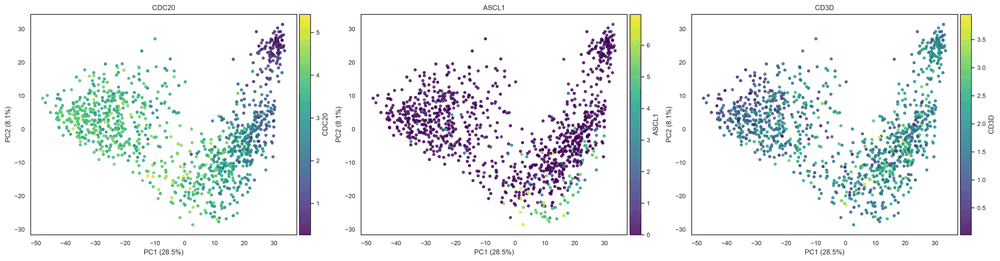

(<Figure size 3900x1000 with 6 Axes>,
 array([<Axes: title={'center': 'CDC20'}, xlabel='PC1 (28.5%)', ylabel='PC2 (8.1%)'>,
        <Axes: title={'center': 'ASCL1'}, xlabel='PC1 (28.5%)', ylabel='PC2 (8.1%)'>,
        <Axes: title={'center': 'CD3D'}, xlabel='PC1 (28.5%)', ylabel='PC2 (8.1%)'>],
       dtype=object))

In [23]:
bk.pl.pca_scatter(adata, color=["CDC20", "ASCL1","CD3D"], point_size=20)

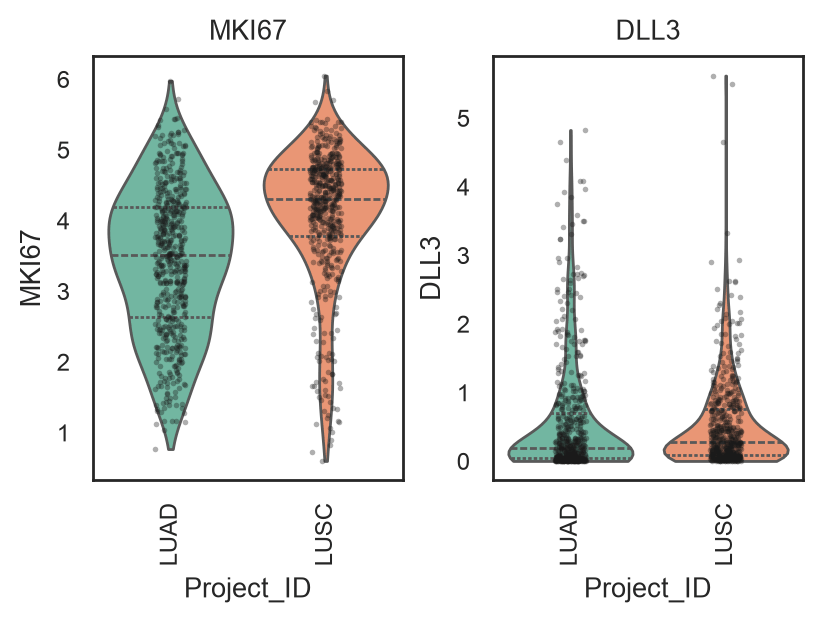

(<Figure size 800x600 with 2 Axes>,
 array([<Axes: title={'center': 'MKI67'}, xlabel='Project_ID', ylabel='MKI67'>,
        <Axes: title={'center': 'DLL3'}, xlabel='Project_ID', ylabel='DLL3'>],
       dtype=object))

In [65]:
bk.pl.violin(
    adata,
    keys=["MKI67", "DLL3"],
    groupby="Project_ID",
    #layer="log1p_cpm",      # or "counts" / None
    rotate_xticks=90,
    figsize=(4, 3),
    save=FIGURES + "violin_Ki67_DLL3.png",
)  

## 6.2. Score gene signatures

### 6.2.1. A dictionary of signatures

In [25]:
# Define signatures
signatures = {
    "Proliferation": ["MKI67", "TOP2A", "CDC20", "CCNB1", "CCNDA2"],
    "T_cell": ["CD3D", "CD3E", "TRBC1"],
    "Neuroendocrine": ["ASCL1", "NEUROD1", "DLL3", "CHGA"],
}

In [26]:
# Compute signature scores
bk.tl.score_genes_dict(
    adata,
    signatures,
    layer="log1p_cpm",
    scale=True,
)

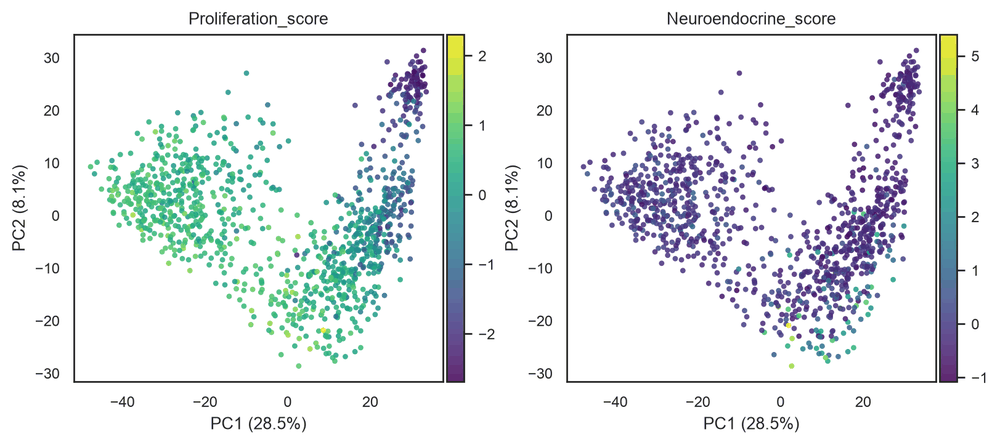

(<Figure size 1600x700 with 4 Axes>,
 array([<Axes: title={'center': 'Proliferation_score'}, xlabel='PC1 (28.5%)', ylabel='PC2 (8.1%)'>,
        <Axes: title={'center': 'Neuroendocrine_score'}, xlabel='PC1 (28.5%)', ylabel='PC2 (8.1%)'>],
       dtype=object))

In [68]:
bk.pl.pca_scatter(
    adata,
    color=["Proliferation_score", "Neuroendocrine_score"],
    cmap="viridis",
    figsize=(4,3.5),
    point_size=10,
    save=FIGURES + "PCA_signatures_example.png",
)

In [28]:
adata.obs.head(3)

,Sample_ID,Patient_ID,Project_ID,gender,race,ajcc_pathologic_tumor_stage,histological_type,initial_pathologic_dx_year,birth_days_to,vital_status,...,leiden_1.5,kmeans_10,kmeans_15,kmeans_20,kmeans_25,kmeans_30,kmeans_5,Proliferation_score,T_cell_score,Neuroendocrine_score
TCGA-97-7938-01A,TCGA-97-7938-01,TCGA-97-7938,LUAD,FEMALE,WHITE,Stage IA,Lung Adenocarcinoma,2011.0,-27980.0,Dead,...,7,5,8,19,2,11,3,-1.364206,-0.419436,-0.363574
TCGA-55-7574-01A,TCGA-55-7574-01,TCGA-55-7574,LUAD,FEMALE,WHITE,Stage IB,Lung Adenocarcinoma,2011.0,-23703.0,Dead,...,7,7,7,5,3,27,3,-0.402567,1.531495,-0.599423
TCGA-05-4250-01A,TCGA-05-4250-01,TCGA-05-4250,LUAD,FEMALE,NaN,Stage IIIA,Lung Adenocarcinoma,2007.0,-29068.0,Dead,...,8,3,0,10,8,7,3,0.465508,0.617936,0.155663


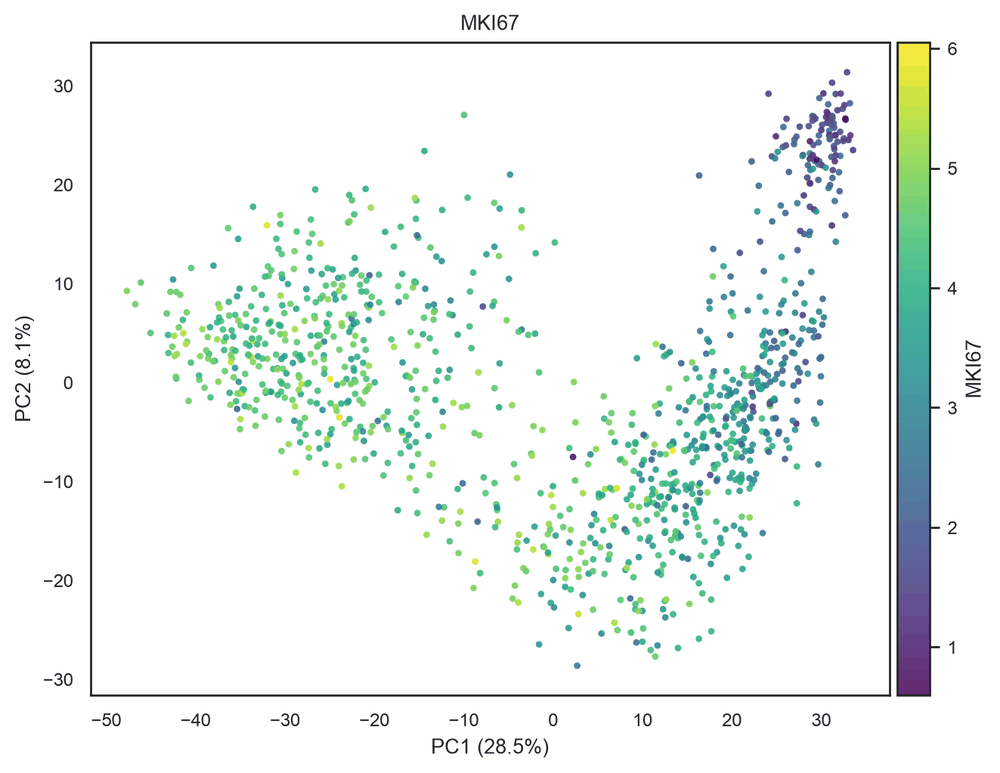

(<Figure size 1300x1000 with 2 Axes>,
 [<Axes: title={'center': 'MKI67'}, xlabel='PC1 (28.5%)', ylabel='PC2 (8.1%)'>])

In [70]:
bk.pl.pca_scatter(
    adata,
    color=["MKI67"],
    cmap="viridis",
    #figsize=(4,3),
    point_size=10,
)

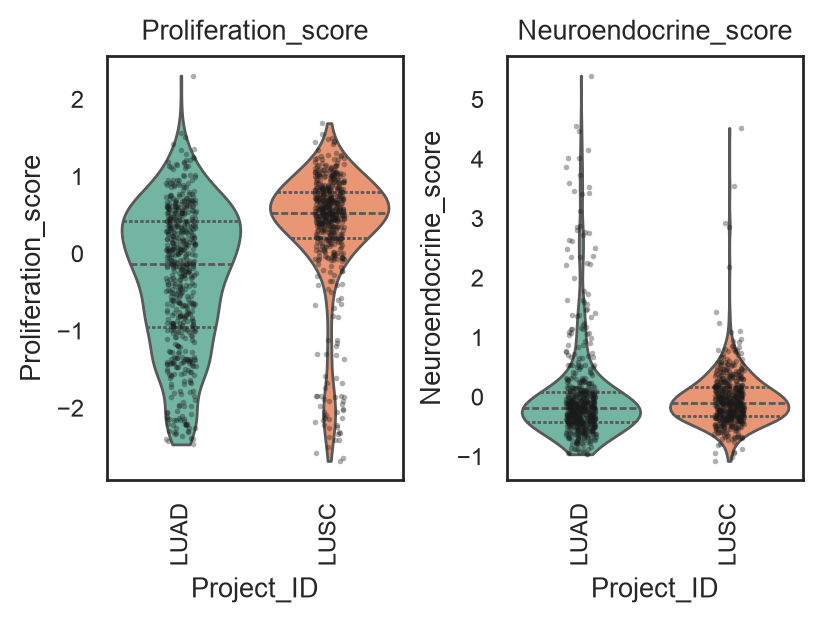

(<Figure size 800x600 with 2 Axes>,
 array([<Axes: title={'center': 'Proliferation_score'}, xlabel='Project_ID', ylabel='Proliferation_score'>,
        <Axes: title={'center': 'Neuroendocrine_score'}, xlabel='Project_ID', ylabel='Neuroendocrine_score'>],
       dtype=object))

In [71]:
bk.pl.violin(
    adata,
    keys=["Proliferation_score", "Neuroendocrine_score"],
    groupby="Project_ID",
    figsize=(4,3),
    rotate_xticks=90,
    save=FIGURES + "violin_signatures_example.png",
)

### 6.2.2. A single signature

In [31]:
ne_score_25 = ['BEX1', 'ASCL1', 'INSM1', 'CHGA', 'TAGLN3', 'KIF5C', 'CRMP1', 'SCG3', 'SYT4', 'RTN1',
               'MYT1', 'SYP', 'KIF1A', 'TMSB15a', 'SYN1', 'SYT11', 'RUNDC3A', 'TFF3', 'CHGB', 'TLCD3B',
               'SH3GL2', 'BSN', 'SEZ6', 'TMSB15B', 'CELF3']


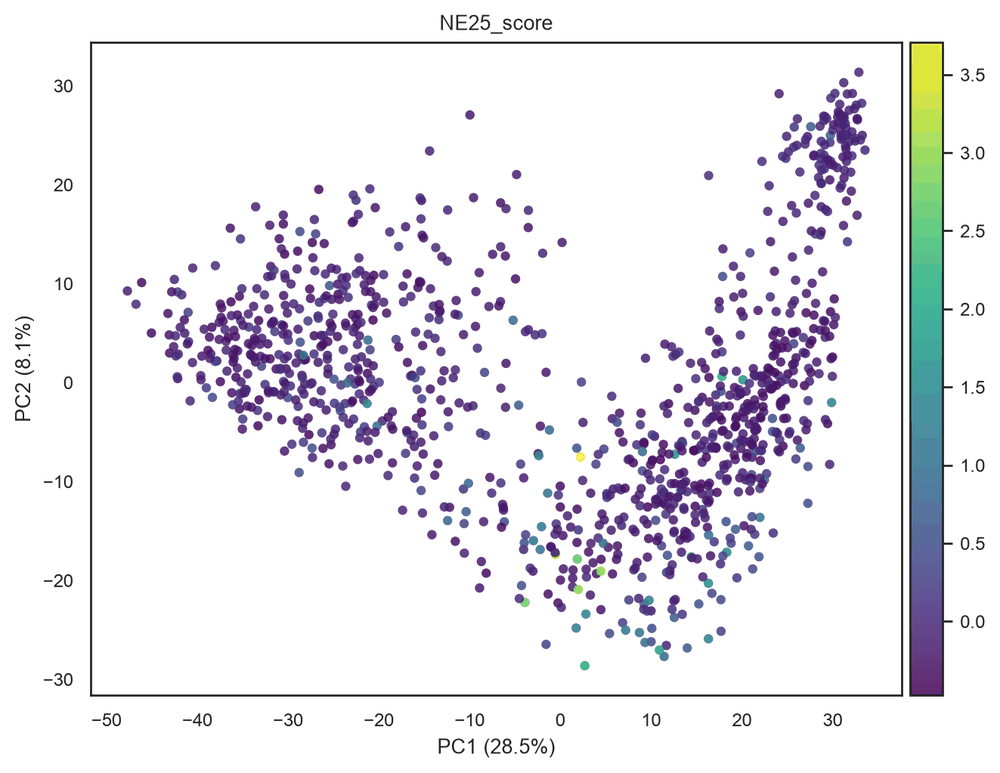

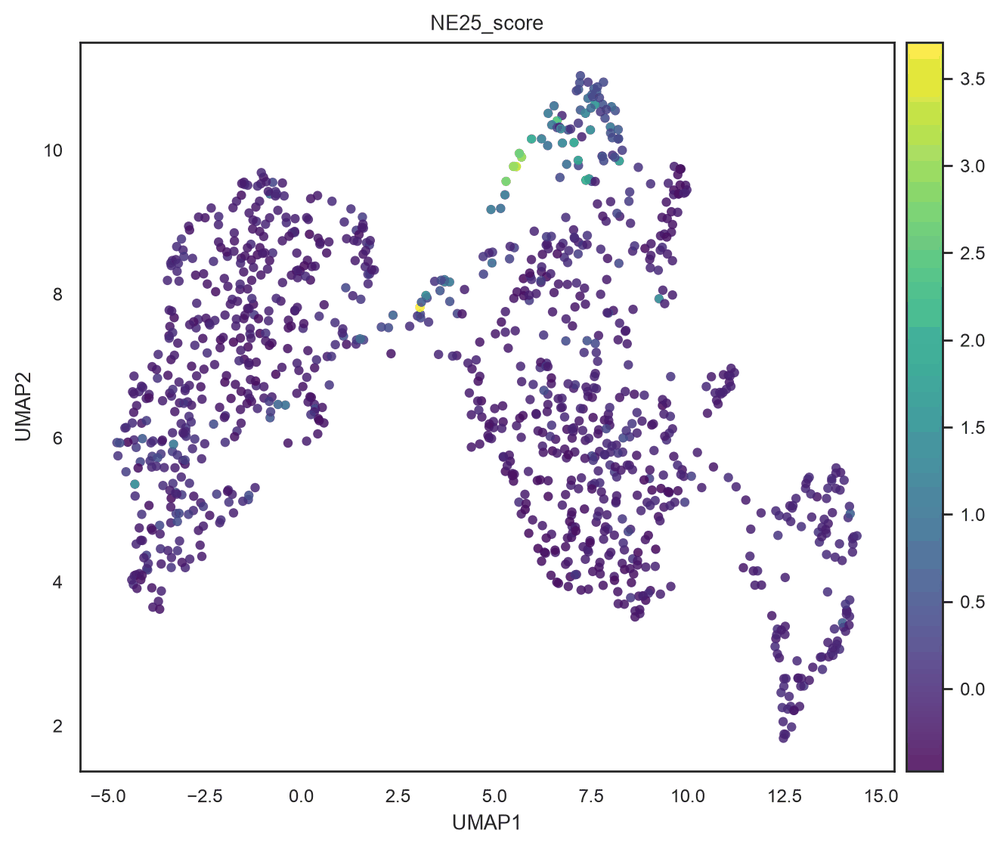

(<Figure size 1300x1100 with 2 Axes>,
 [<Axes: title={'center': 'NE25_score'}, xlabel='UMAP1', ylabel='UMAP2'>])

In [73]:
bk.tl.score_genes(adata, ne_score_25, score_name="NE25_score", layer="log1p_cpm")

# Plot on PCA/UMAP as continuous color (after your pca_scatter/umap changes)
bk.pl.pca_scatter(adata, color="NE25_score", cmap="viridis", 
                  #figsize=(3,2.5), 
                  point_size=20)
bk.pl.umap(adata, color="NE25_score", cmap="viridis", 
           #figsize=(4,3), 
           point_size=20)

### 6.2.3. Cell cycle status

This is not very informative in bulk RNAseq data and simply correlates with increased proliferation, but it may be useful to separate specific subgroups of proliferating vs. less proliferating samples in the same tumor type

In [33]:
# Example gene lists (use your preferred human cell-cycle sets)
cell_cycle_genes = {
"s_genes": ["MCM5", "PCNA", "TYMS", "MCM2", "MCM4", "RRM1", "UNG", "GINS2"],
"g2m_genes": ["HMGB2", "CDK1", "NUSAP1", "UBE2C", "BIRC5", "TPX2", "TOP2A"],
}

In [34]:
bk.tl.score_genes_cell_cycle(
    adata,
    s_genes=cell_cycle_genes["s_genes"],
    g2m_genes=cell_cycle_genes["g2m_genes"],
    layer="log1p_cpm",   # or whatever you use for expression scoring
    scale=True,          # optional; often helps if genes have different ranges
)

adata.obs[["S_score", "G2M_score", "phase"]].head()

,S_score,G2M_score,phase
TCGA-97-7938-01A,-1.076437,-1.467979,G1
TCGA-55-7574-01A,-0.693559,-0.454024,G1
TCGA-05-4250-01A,0.452565,0.770776,G2M
TCGA-55-6979-11A,-1.526413,-1.686550,G1
TCGA-95-A4VK-01A,-0.511355,-0.552639,G1


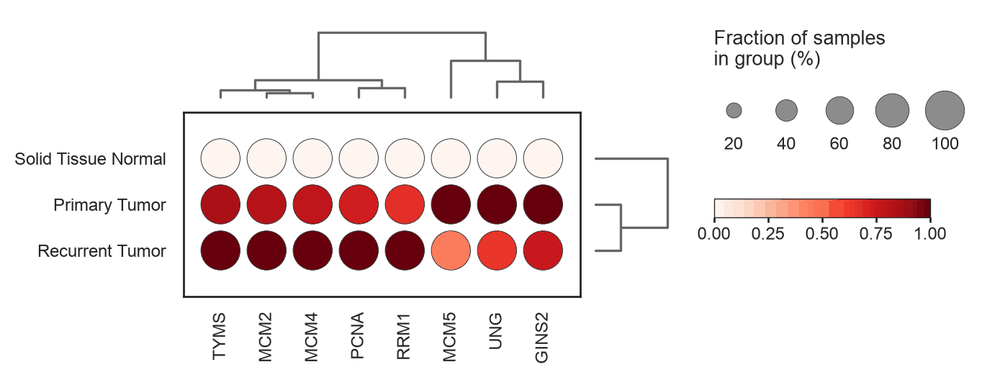

(<Figure size 1349.22x488 with 5 Axes>, <Axes: >)

In [75]:
bk.pl.dotplot(adata, var_names=cell_cycle_genes["s_genes"], groupby="sample_type",
              swap_axes=False,
              dendrogram_top=True,
              dendrogram_rows=True,
              cluster_cols=True,
              cluster_rows=True,
              standard_scale="var",
              colorbar_title=None,
              save=FIGURES + "dotplot_cell_cycle_example.png",
             )

In [36]:
cc_names = {
    "S-phase": ["MCM2", "PCNA", "TYMS"],
    "G2/M": ["CDC20", "AURKB", "PLK1"],
}

In [37]:
gene_names = {
    "Proliferation": ["MCM2", "CDC20", "PLK1"],
    "Neuroendocrine": ["ASCL1", "GFAP", "DLL3"],
}

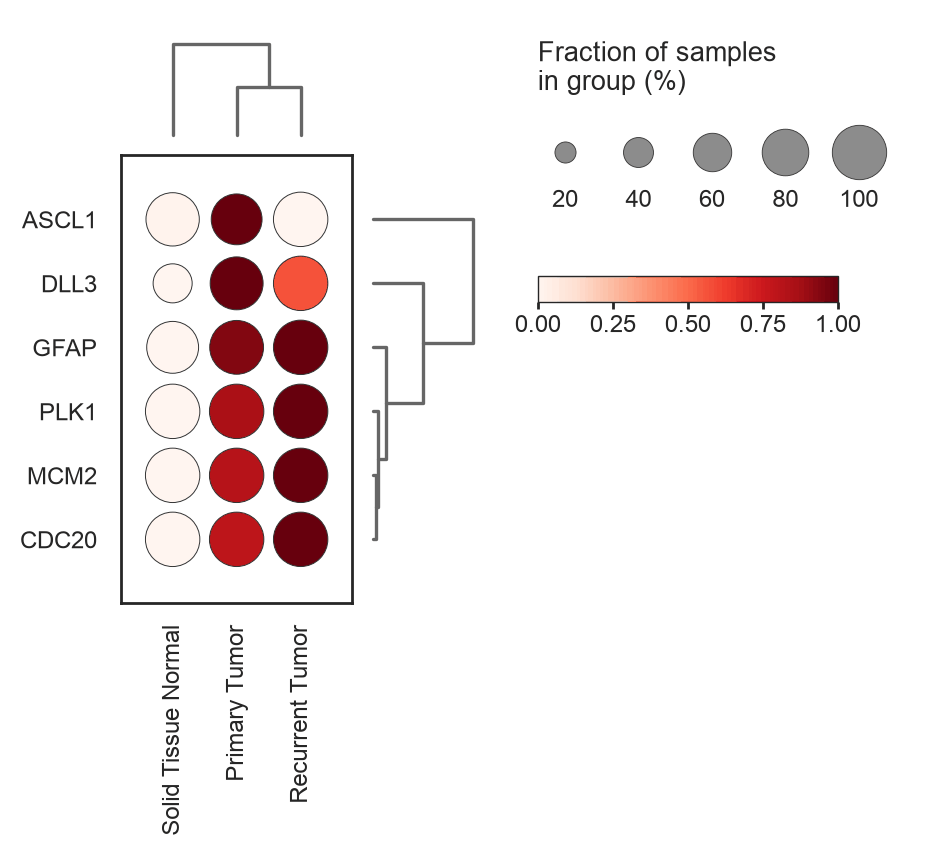

(<Figure size 895.56x818.656 with 5 Axes>, <Axes: >)

In [76]:
bk.pl.dotplot(adata, var_groups=gene_names, groupby="sample_type",
              swap_axes=True,
              dendrogram_top=True,
              dendrogram_rows=True,
              cluster_cols=True,
              cluster_rows=True,
              standard_scale="var",
              colorbar_title=None,
              save=FIGURES + "dotplot_example.png",
             )

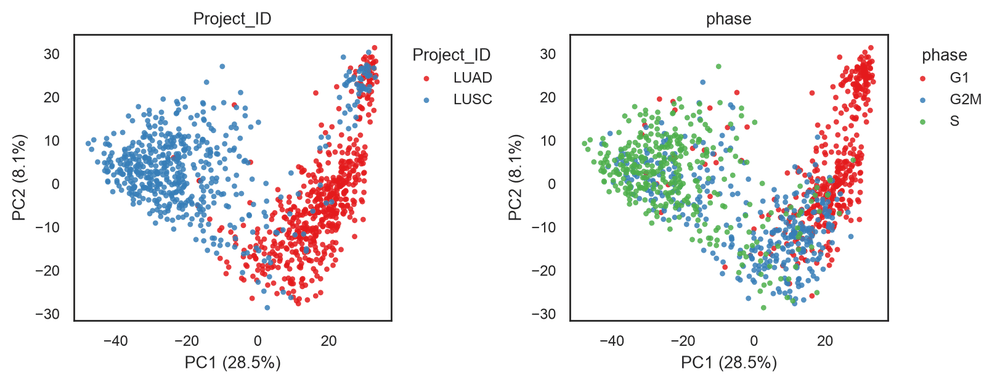

(<Figure size 1600x600 with 2 Axes>,
 array([<Axes: title={'center': 'Project_ID'}, xlabel='PC1 (28.5%)', ylabel='PC2 (8.1%)'>,
        <Axes: title={'center': 'phase'}, xlabel='PC1 (28.5%)', ylabel='PC2 (8.1%)'>],
       dtype=object))

In [78]:
bk.pl.pca_scatter(adata, color=["Project_ID", "phase"], figsize=(4,3),
                  save=FIGURES+"PCA_projectID_cellcycle_phase.png", point_size=10,
                 )

Save .h5ad file with new signatures and gene scores stored in adata.obs

In [41]:
# HDF5 forbids '/' in keys; rename them before writing
bk.pp.make_h5ad_safe(adata)
adata.write(H5AD, compression="gzip")


# 5. Data Exploration
<a id="exploration"></a>

## 5.1. General bidimensional representation

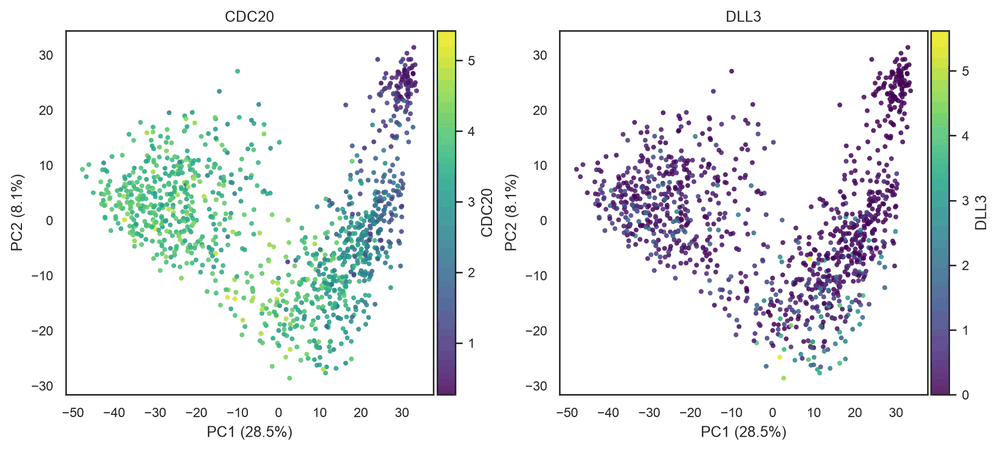

(<Figure size 1800x800 with 4 Axes>,
 array([<Axes: title={'center': 'CDC20'}, xlabel='PC1 (28.5%)', ylabel='PC2 (8.1%)'>,
        <Axes: title={'center': 'DLL3'}, xlabel='PC1 (28.5%)', ylabel='PC2 (8.1%)'>],
       dtype=object))

In [83]:
bk.pl.pca_scatter(adata, color=["CDC20", "DLL3"], point_size=10,
          figsize=(4.5,4))

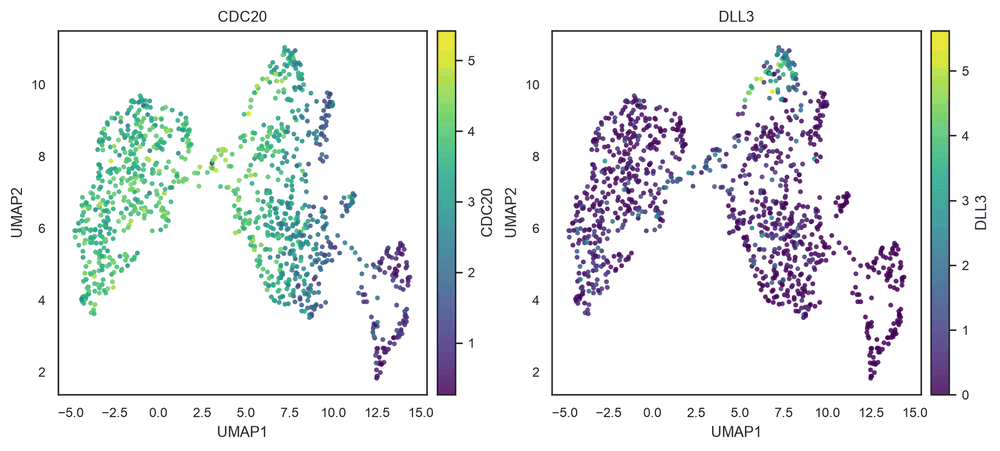

(<Figure size 1800x800 with 4 Axes>,
 array([<Axes: title={'center': 'CDC20'}, xlabel='UMAP1', ylabel='UMAP2'>,
        <Axes: title={'center': 'DLL3'}, xlabel='UMAP1', ylabel='UMAP2'>],
       dtype=object))

In [84]:
bk.pl.umap(adata, color=["CDC20", "DLL3"], point_size=10,
          figsize=(4.5,4))

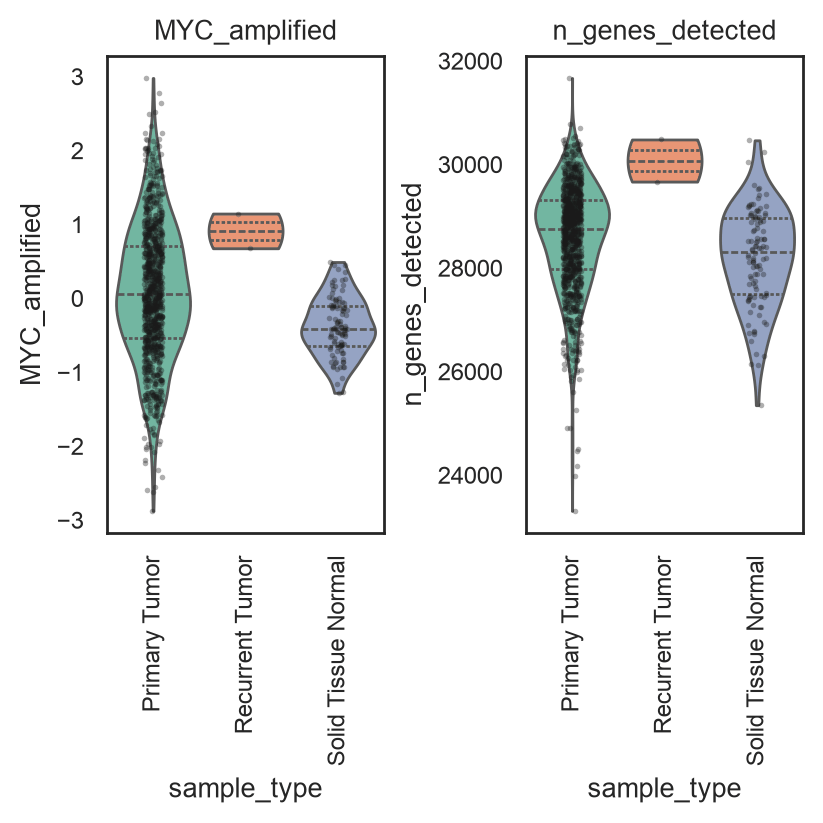

(<Figure size 800x800 with 2 Axes>,
 array([<Axes: title={'center': 'MYC_amplified'}, xlabel='sample_type', ylabel='MYC_amplified'>,
        <Axes: title={'center': 'n_genes_detected'}, xlabel='sample_type', ylabel='n_genes_detected'>],
       dtype=object))

In [86]:
bk.pl.violin(
    adata,
    keys=["MYC_amplified", "n_genes_detected"],
    groupby="sample_type",
    #order=["LumA", "LumB", "Her2", "Basal", "Normal"],
    figsize=(4,4),
    rotate_xticks=90,
    save=FIGURES + "violin_MYC_qc_genes.png",
)

## 5.2. Select only one/a few categories

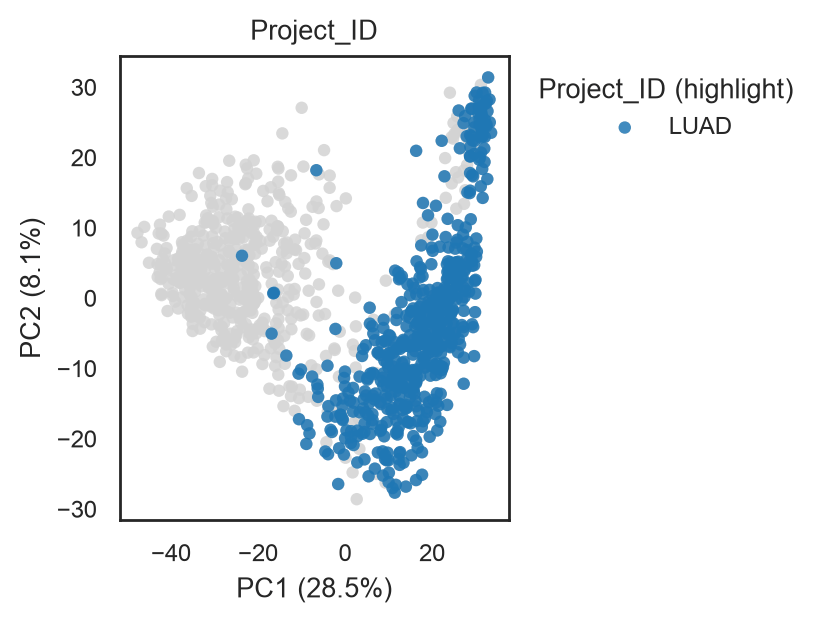

(<Figure size 800x600 with 1 Axes>,
 [<Axes: title={'center': 'Project_ID'}, xlabel='PC1 (28.5%)', ylabel='PC2 (8.1%)'>])

In [87]:
bk.pl.pca_scatter(
    adata,
    color="Project_ID",
    highlight=["LUAD"],
    palette="tab20",
    figsize=(4,3),
    save=FIGURES + "PCA_only_lung_filtered.png",
)

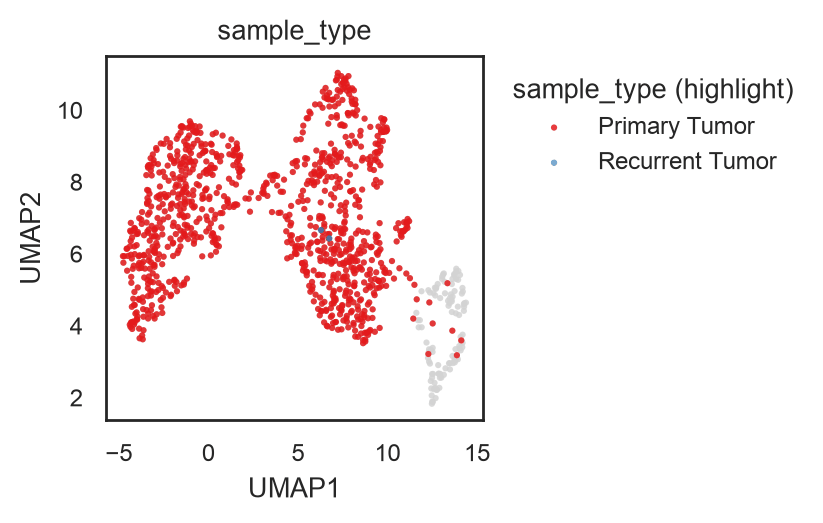

(<Figure size 800x500 with 1 Axes>,
 [<Axes: title={'center': 'sample_type'}, xlabel='UMAP1', ylabel='UMAP2'>])

In [88]:
bk.pl.umap(adata, color="sample_type", point_size=5, 
           highlight=["Primary Tumor", "Recurrent Tumor"],
          figsize=(4,2.5))

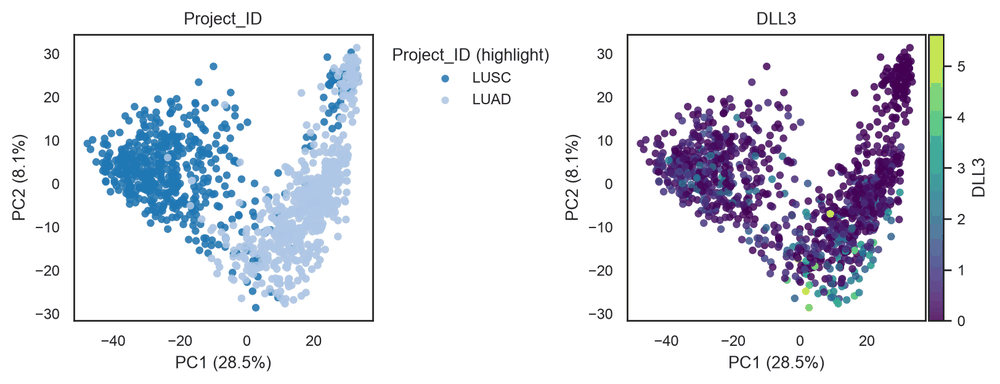

(<Figure size 1600x600 with 3 Axes>,
 array([<Axes: title={'center': 'Project_ID'}, xlabel='PC1 (28.5%)', ylabel='PC2 (8.1%)'>,
        <Axes: title={'center': 'DLL3'}, xlabel='PC1 (28.5%)', ylabel='PC2 (8.1%)'>],
       dtype=object))

In [89]:
bk.pl.pca_scatter(
    adata,
    color=["Project_ID", "DLL3"],
    highlight=["LUSC", "LUAD"],
    palette="tab20",
    figsize=(4,3),
)

## 5.3. Subfilters

In [52]:
adata.shape
print("Number of cells:", adata.n_obs, "- Number of genes:", adata.n_vars)

Number of cells: 1108 - Number of genes: 31891


Define subsets of the large dataset

In [6]:
filter = (adata.obs.Project_ID == "LUAD")
adata_luad = adata[filter]
print("Selected subset: Number of cells:", adata_luad.n_obs, "- Number of genes:", adata_luad.n_vars)

Selected subset: Number of cells: 567 - Number of genes: 31891


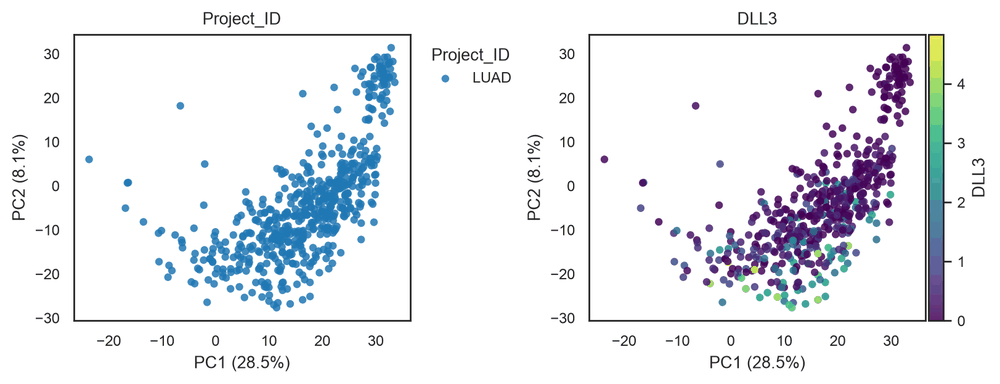

(<Figure size 1600x600 with 3 Axes>,
 array([<Axes: title={'center': 'Project_ID'}, xlabel='PC1 (28.5%)', ylabel='PC2 (8.1%)'>,
        <Axes: title={'center': 'DLL3'}, xlabel='PC1 (28.5%)', ylabel='PC2 (8.1%)'>],
       dtype=object))

In [90]:
bk.pl.pca_scatter(adata_luad, color=["Project_ID", "DLL3"], palette="tab20",
                  figsize=(4,3),
                  save=FIGURES + "PCA_adata_lung_example.png",
                 )

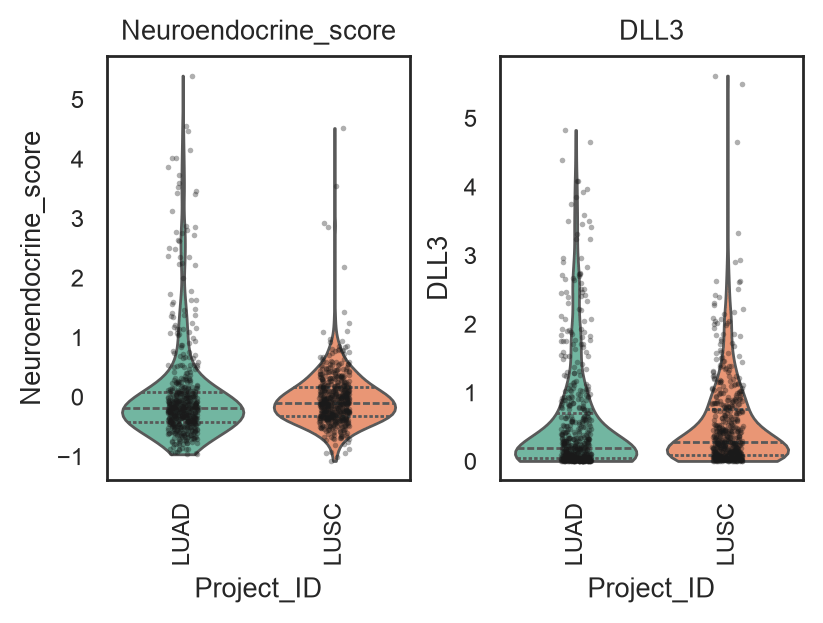

(<Figure size 800x600 with 2 Axes>,
 array([<Axes: title={'center': 'Neuroendocrine_score'}, xlabel='Project_ID', ylabel='Neuroendocrine_score'>,
        <Axes: title={'center': 'DLL3'}, xlabel='Project_ID', ylabel='DLL3'>],
       dtype=object))

In [91]:
bk.pl.violin(
    adata,                                          # complete adata
    keys=["Neuroendocrine_score", "DLL3"],
    groupby="Project_ID",
    order=["LUAD", "LUSC"],                 # but only these groups
    figsize=(4,3),
    rotate_xticks=90,
    save=FIGURES + "violin_filtered_NE_score_DLL3_lonly_lung.png",
)

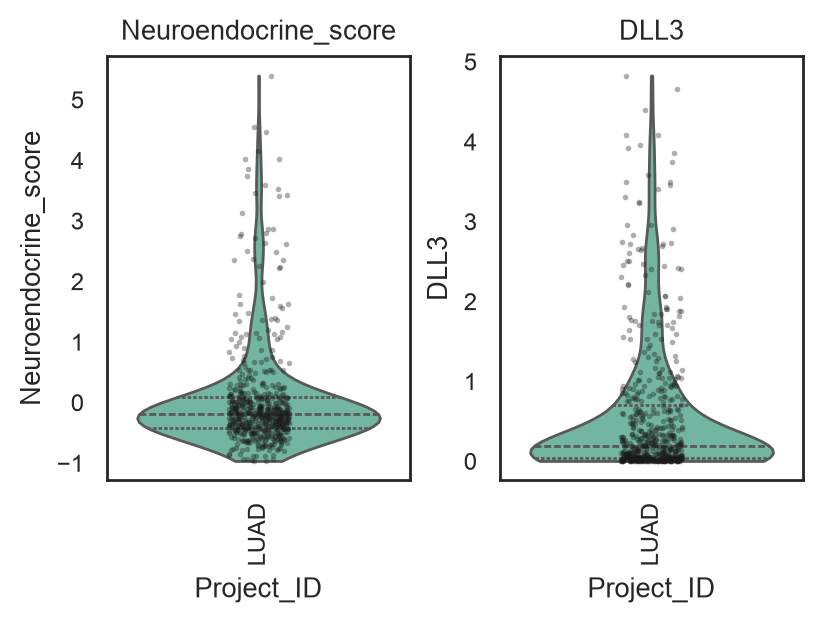

(<Figure size 800x600 with 2 Axes>,
 array([<Axes: title={'center': 'Neuroendocrine_score'}, xlabel='Project_ID', ylabel='Neuroendocrine_score'>,
        <Axes: title={'center': 'DLL3'}, xlabel='Project_ID', ylabel='DLL3'>],
       dtype=object))

In [94]:
bk.pl.violin(
    adata_luad,                                          # only adata_lung
    keys=["Neuroendocrine_score", "DLL3"],
    groupby="Project_ID",
    figsize=(4,3),
    rotate_xticks=90,
    save=FIGURES + "violin_adata_lung_NE_score_DLL3.png",
)

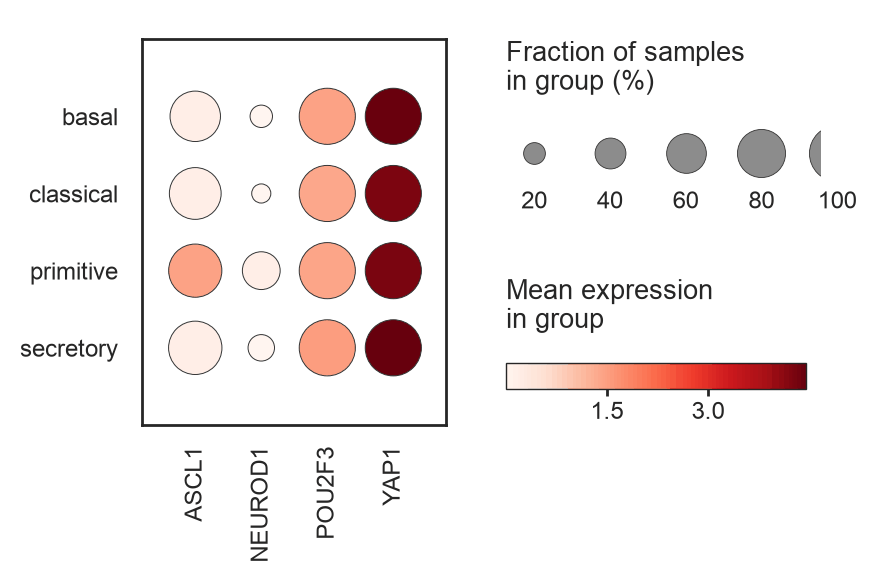

(<Figure size 800x545.867 with 3 Axes>, <Axes: >)

In [95]:
bk.pl.dotplot(adata, var_names=["ASCL1","NEUROD1","POU2F3","YAP1"], groupby="Subtype_mRNA",
             figsize=(4,2),
             save=FIGURES + "dotplot_genes_projectID_example.png")

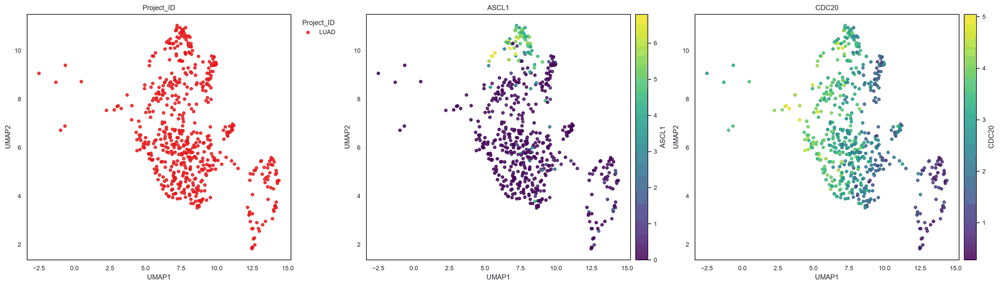

(<Figure size 3900x1100 with 5 Axes>,
 array([<Axes: title={'center': 'Project_ID'}, xlabel='UMAP1', ylabel='UMAP2'>,
        <Axes: title={'center': 'ASCL1'}, xlabel='UMAP1', ylabel='UMAP2'>,
        <Axes: title={'center': 'CDC20'}, xlabel='UMAP1', ylabel='UMAP2'>],
       dtype=object))

In [96]:
bk.pl.umap(adata_luad, color=["Project_ID", "ASCL1", "CDC20"])

#### Save .h5ad files

In [97]:
# HDF5 forbids '/' in keys; rename them before writing
bk.pp.make_h5ad_safe(adata)
adata.write(H5AD, compression="gzip")

# save also LUAD
adata_luad.write(DATA_H5AD + "TCGA_lung_LUAD.h5ad", compression="gzip")


# 6. Correlations & Associations
<a id="correlations"></a>

In [98]:
adata.obs.columns

Index(['Sample_ID', 'Patient_ID', 'Project_ID', 'gender', 'race',
       'ajcc_pathologic_tumor_stage', 'histological_type',
       'initial_pathologic_dx_year', 'birth_days_to', 'vital_status',
       ...
       'kmeans_25', 'kmeans_30', 'kmeans_5', 'Proliferation_score',
       'T_cell_score', 'Neuroendocrine_score', 'NE25_score', 'S_score',
       'G2M_score', 'phase'],
      dtype='str', length=411)

## 6.1. General correlation heatmap

Correlation between genes (gene expression) or between samples (numeric observations/metadata)  
It may be useful as QC (when `use="genes"`) or general correlation between clinical data (`use="samples"`).

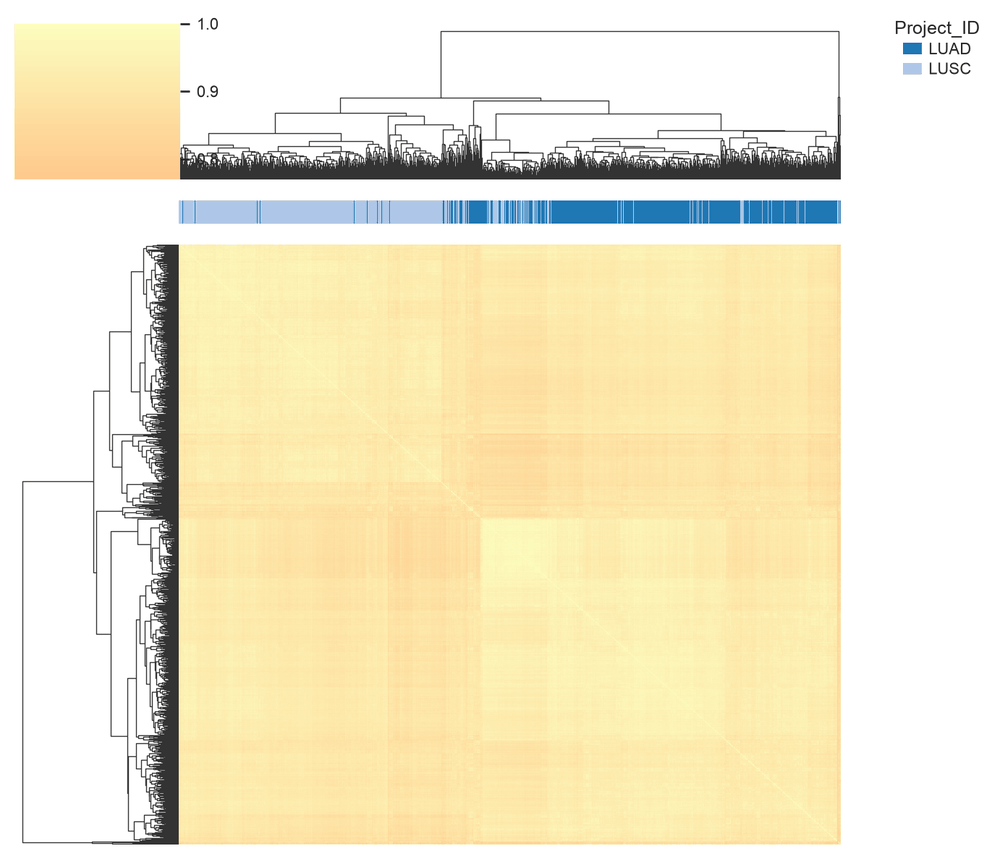

In [101]:
cg = bk.pl.corr_heatmap(
    adata,
    use="samples",               # "genes", "samples"
    method="pearson",               # "pearson", "spearman"
    col_colors="Project_ID",
    dendrogram=True,
    remove_cbar_label=True,
    dendrogram_gap=0.08,
    right_margin=1.02,
    cmap="magma",
    figsize=(6,6),
    save=FIGURES + "corr_heatmap_example_lung.png",
)

## 6.2. Correlations between numerical data

### 6.2.1. Gene–gene correlations

In [102]:
# 1) One gene vs ALL genes
df_gene_corr = bk.tl.gene_gene_correlations(
    adata,
    gene="DLL3",
    top_n=50000,
)
df_gene_corr = df_gene_corr.sort_values(by="r", ascending=False)
df_gene_corr.head(3)

,query_gene,gene,r,pval,n,qval,method,batch_key,batch_mode
0,DLL3,ASCL1,0.671383,4.397740e-146,1108,1.402439e-141,pearson,None,none
1,DLL3,CALCA,0.621612,1.931498e-119,1108,3.079774e-115,pearson,None,none
2,DLL3,CALCB,0.591979,9.673394e-106,1108,1.028282e-101,pearson,None,none


In [103]:
df_gene_corr.tail(3)

,query_gene,gene,r,pval,n,qval,method,batch_key,batch_mode
152,DLL3,RAB27B,-0.389185,2.197651e-41,1108,4.580595e-39,pearson,None,none
144,DLL3,CAV2,-0.396406,5.287380e-43,1108,1.162859e-40,pearson,None,none
92,DLL3,AHNAK,-0.423026,2.500547e-49,1108,8.574458e-47,pearson,None,none


In [104]:
# save to an external csv/tsv/excel table
df_gene_corr.to_csv(TABLES + "DLL3_gene_correlations.tsv", sep="\t")

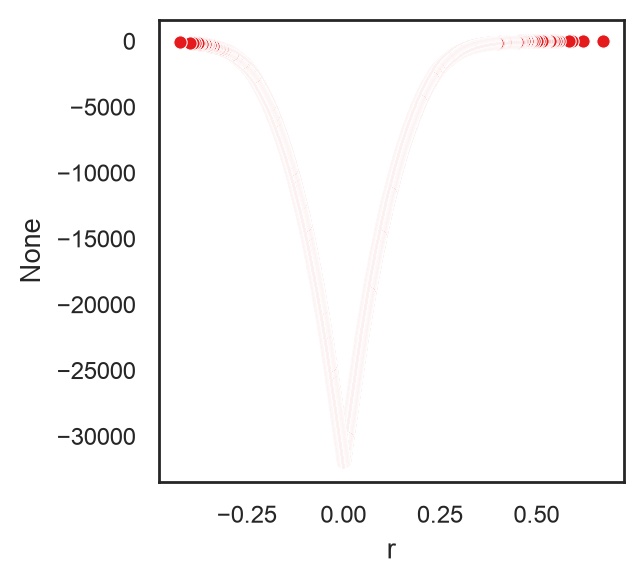

In [106]:
plt.figure(figsize=(3,3))
sns.scatterplot(y=df_gene_corr.index * (-1), x=df_gene_corr["r"])
plt.show()

In [107]:
# 2) One gene vs a pathway / gene list

gene_list = ["DLL3", "SOX2", "NEUROD1", "MYCL", "RB1", "MYC", "YAP1"]

df_gene_list_corr = bk.tl.gene_gene_correlations(
    adata,
    gene="ASCL1",
    genes=gene_list,
)
df_gene_list_corr

,query_gene,gene,r,pval,n,qval,method,batch_key,batch_mode
0,ASCL1,DLL3,0.671383,4.397740e-146,1108,3.078418e-145,pearson,None,none
1,ASCL1,NEUROD1,0.532645,3.284720e-82,1108,1.149652e-81,pearson,None,none
2,ASCL1,MYCL,0.332472,5.279417e-30,1108,1.231864e-29,pearson,None,none
3,ASCL1,YAP1,-0.326274,6.771318e-29,1108,1.184981e-28,pearson,None,none
4,ASCL1,MYC,-0.161284,6.741944e-08,1108,9.438722e-08,pearson,None,none
5,ASCL1,SOX2,0.111319,2.049760e-04,1108,2.268994e-04,pearson,None,none
6,ASCL1,RB1,-0.110551,2.268994e-04,1108,2.268994e-04,pearson,None,none


Gene-gene correlation plots

In [6]:
selected_genes = ["PLK1", "CDC20", "DLL3", "GFAP", "NEUROD1", "MKI67", "ASCL1", "ESR1", "CCND1"]

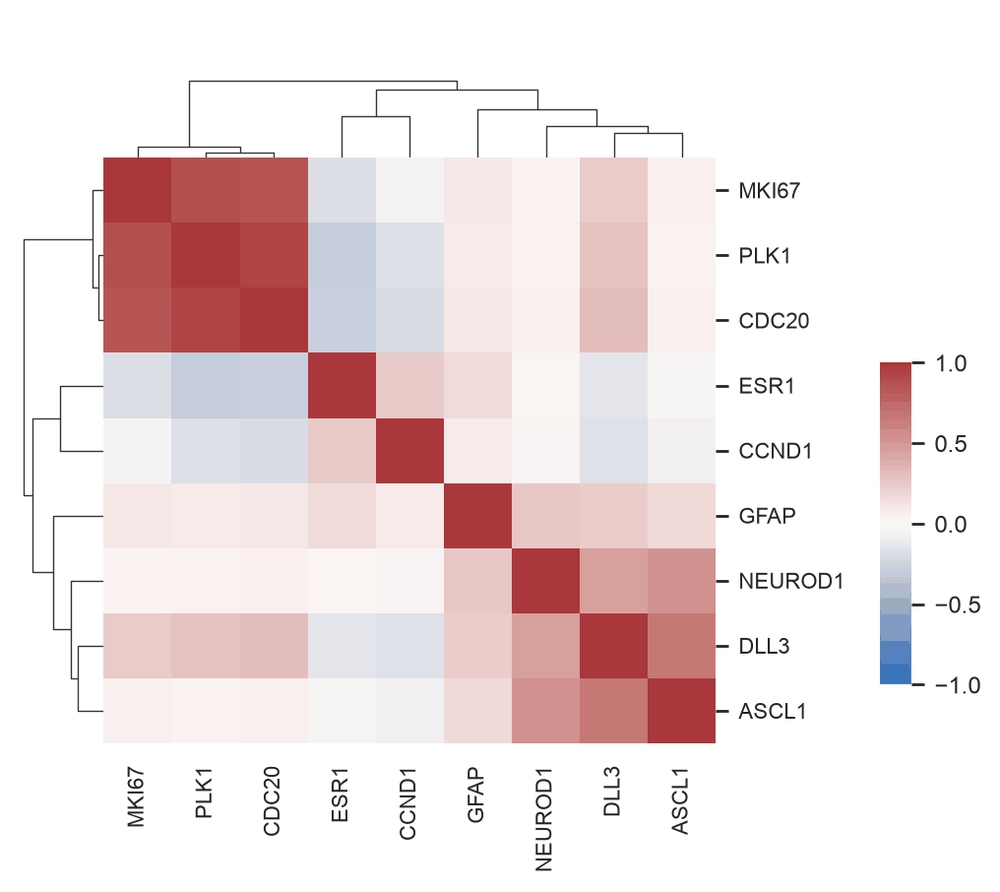

(            MKI67      PLK1     CDC20      ESR1     CCND1      GFAP   NEUROD1  \
 MKI67    1.000000  0.877101  0.844447 -0.187044 -0.059031  0.097022  0.036785   
 PLK1     0.877101  1.000000  0.932241 -0.295131 -0.174334  0.088091  0.039677   
 CDC20    0.844447  0.932241  1.000000 -0.278887 -0.196197  0.098754  0.053571   
 ESR1    -0.187044 -0.295131 -0.278887  1.000000  0.249968  0.159956  0.020141   
 CCND1   -0.059031 -0.174334 -0.196197  0.249968  1.000000  0.086693  0.030630   
 GFAP     0.097022  0.088091  0.098754  0.159956  0.086693  1.000000  0.257367   
 NEUROD1  0.036785  0.039677  0.053571  0.020141  0.030630  0.257367  1.000000   
 DLL3     0.239018  0.282018  0.305130 -0.147682 -0.167737  0.232023  0.456329   
 ASCL1    0.056669  0.043205  0.056173 -0.042548 -0.079926  0.171716  0.532645   
 
              DLL3     ASCL1  
 MKI67    0.239018  0.056669  
 PLK1     0.282018  0.043205  
 CDC20    0.305130  0.056173  
 ESR1    -0.147682 -0.042548  
 CCND1   -0.167737 -0.0

In [8]:
bk.pl.gene_panel_correlation_heatmap(adata, genes=selected_genes,
                                     cluster=True,
                                     #figsize=(6,6),
                                     title=" ",
                                     save=FIGURES + "gene_gene_list_correlation.png",
                                    )

#### Batch-aware correlation between genes and observations

In [9]:
# 1) Residualize batch (+ optional covariates) then correlate
df = bk.tl.gene_gene_correlations(
    adata, gene="ASCL1", layer="log1p_cpm",
    batch_key="gender",                         # any batch-related metadata
    batch_mode="residualize",
)

In [10]:
# 2) Z-score within each batch, then correlate pooled
df = bk.tl.gene_gene_correlations(
    adata, gene="ASCL1",
    batch_key="gender", batch_mode="within_batch",
)

In [11]:
# 3) Meta-analyze correlations across batches
df = bk.tl.gene_gene_correlations(
    adata, gene="ASCL1",
    batch_key="gender", batch_mode="meta",
)

### 8.2.2. Gene versus Observations Correlations

In [12]:
# One gene vs all numeric metadata

df_gene_obs_corr = bk.tl.top_gene_obs_correlations(
    adata,
    gene="DLL3",
    layer="log1p_cpm",
    method="spearman",
    top_n=1000,
)
df_gene_obs_corr.head()

,gene,obs,r,pval,n,qval,method,batch_key,batch_mode
0,DLL3,Neuroendocrine_score,0.560829,8.555400e-93,1108,2.284292e-90,spearman,None,none
1,DLL3,RESPONSE_TO_ANDROGEN,0.510236,6.634434e-73,1084,8.856970e-71,spearman,None,none
2,DLL3,GP5_MYC_targets_TERT,0.492486,2.654782e-67,1084,2.362756e-65,spearman,None,none
3,DLL3,GP1_Proliferation_DNA_repair,0.479829,1.666562e-63,1084,1.112430e-61,spearman,None,none
4,DLL3,Module11_Prolif_score,0.454636,2.104404e-56,1084,1.123752e-54,spearman,None,none


In [13]:
df_gene_obs_corr = df_gene_obs_corr.sort_values(by="r", ascending=False)
df_gene_obs_corr.head()

,gene,obs,r,pval,n,qval,method,batch_key,batch_mode
0,DLL3,Neuroendocrine_score,0.560829,8.555400e-93,1108,2.284292e-90,spearman,None,none
1,DLL3,RESPONSE_TO_ANDROGEN,0.510236,6.634434e-73,1084,8.856970e-71,spearman,None,none
2,DLL3,GP5_MYC_targets_TERT,0.492486,2.654782e-67,1084,2.362756e-65,spearman,None,none
3,DLL3,GP1_Proliferation_DNA_repair,0.479829,1.666562e-63,1084,1.112430e-61,spearman,None,none
4,DLL3,Module11_Prolif_score,0.454636,2.104404e-56,1084,1.123752e-54,spearman,None,none


In [14]:
df_gene_obs_corr.tail()

,gene,obs,r,pval,n,qval,method,batch_key,batch_mode
15,DLL3,ALK_PATHWAY,-0.378452,3.055049e-38,1084,5.098113e-37,spearman,None,none
13,DLL3,MHC.II_19272155,-0.400910,4.081127e-43,1084,7.783293e-42,spearman,None,none
12,DLL3,MHC2_21978456,-0.404969,4.885904e-44,1084,1.003489e-42,spearman,None,none
7,DLL3,samples.sample_type_id,-0.427300,2.128434e-50,1108,6.314356e-49,spearman,None,none
8,DLL3,sample_type_id,-0.427300,2.128434e-50,1108,6.314356e-49,spearman,None,none


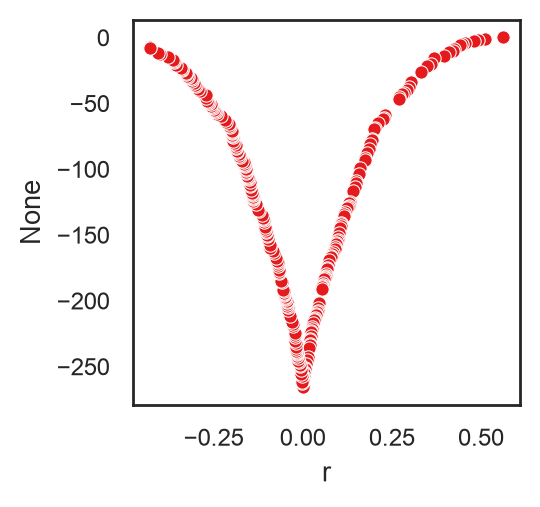

In [15]:
# Volcano-style plot
plt.figure(figsize=(2.5, 2.5))
sns.scatterplot(y=df_gene_obs_corr.index*(-1), x=df_gene_obs_corr["r"],)
plt.show()

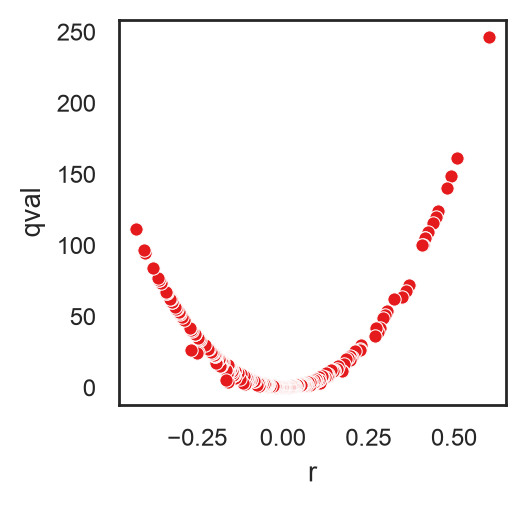

In [121]:
# Volcano-style plot
# This plot gives a problem with pval/qval=0
plt.figure(figsize=(2.5, 2.5))
sns.scatterplot(y=-np.log(df_gene_obs_corr["qval"]), x=df_gene_obs_corr["r"],)
plt.show()

### 6.2.3. Wide matrix (focus × against) + p/q matrices
Correlation between numeric values (genes, scores, numeric metadata) and other numeric observations  


In [23]:
selected_obs = ["Neuroendocrine_score"]                         # One: "Purity" or several: ["Purity", "TMB"]
obs_list = ["OS.time", "DSS.time", "PFI.time", 
            "Interferon_19272155", "ai1", "lst1", "hrd-loh", "HRD", "S_score",
            "Leuk", "Stroma", "purity", "ploidy",
           ]

# If necessary:
#adata.obs[obs_list] = adata.obs[obs_list].apply(pd.to_numeric, errors="coerce")
#adata.obs[obs_list] = adata.obs[obs_list].astype(float)          # float, int, "category"

In [24]:
# Ensure they are imported as numeric data
adata.obs[obs_list] = adata.obs[obs_list].apply(pd.to_numeric, errors="coerce")

In [25]:
R, P, Q = bk.tl.obs_obs_corr_matrix(
    adata, focus=selected_obs, against=obs_list, return_p=True, return_q=True,)

res = pd.concat([R, P, Q], keys=["R", "p-val", "q-val"], #names=["source", "row"]
)
res.index = res.index.droplevel(1)
res = res.T.sort_values(by="R", ascending=False)
res

,R,p-val,q-val
S_score,0.220816,1.054757e-13,1.371184e-12
lst1,0.188689,2.585522e-09,1.120393e-08
ai1,0.163322,2.697394e-07,8.766530e-07
HRD,0.160710,4.190328e-07,1.089485e-06
ploidy,0.150776,2.099904e-06,4.549792e-06
purity,0.091666,4.060181e-03,5.864706e-03
hrd-loh,0.063595,4.644531e-02,6.037891e-02
PFI.time,0.010553,7.273561e-01,8.596027e-01
OS.time,-0.002333,9.385843e-01,9.385843e-01
DSS.time,-0.002333,9.385843e-01,9.385843e-01


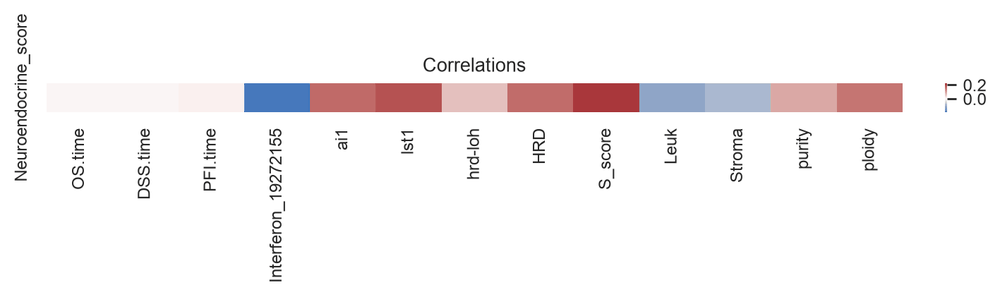

(<Figure size 1400x200 with 2 Axes>, <Axes: title={'center': 'Correlations'}>)

In [26]:
bk.tl.plot_corr_heatmap(R, title="Correlations", figsize=(7,1),
                       )

### 6.2.4. Plot scatter with hue

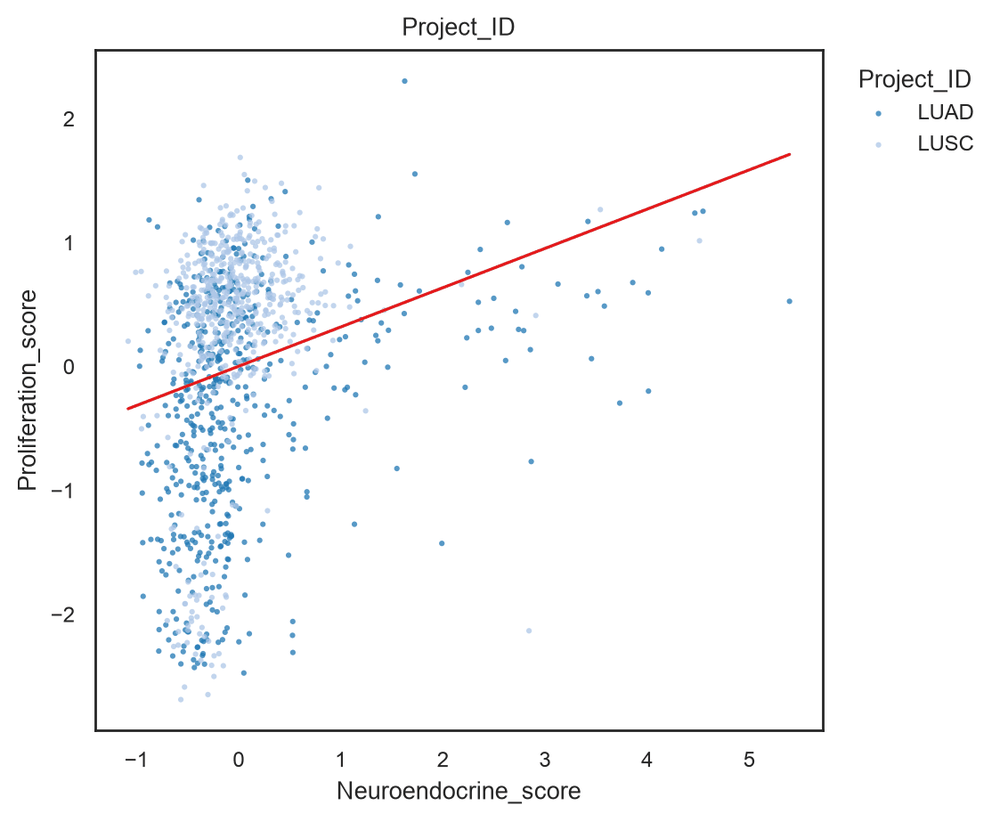

(<Figure size 1100x900 with 1 Axes>,
 array([<Axes: title={'center': 'Project_ID'}, xlabel='Neuroendocrine_score', ylabel='Proliferation_score'>],
       dtype=object),
 [{'n': 1108,
   'pearson_r': 0.24720784406677243,
   'pearson_p': 6.863925694622921e-17,
   'spearman_rho': 0.34634652365866553,
   'spearman_p': 1.4079035810271415e-32,
   'slope': 0.31695792454056154,
   'intercept': 1.3439761519269638e-15}])

In [27]:
bk.pl.corrplot(
    adata,
    x="Neuroendocrine_score",
    y="Proliferation_score",
    color="Project_ID",
    cmap="viridis",
    annotate=False,
    legend=True,
    point_size=5,
    #figsize=(2.8,2.5),
    save=FIGURES + "corr_plot_hue_example.png",
)

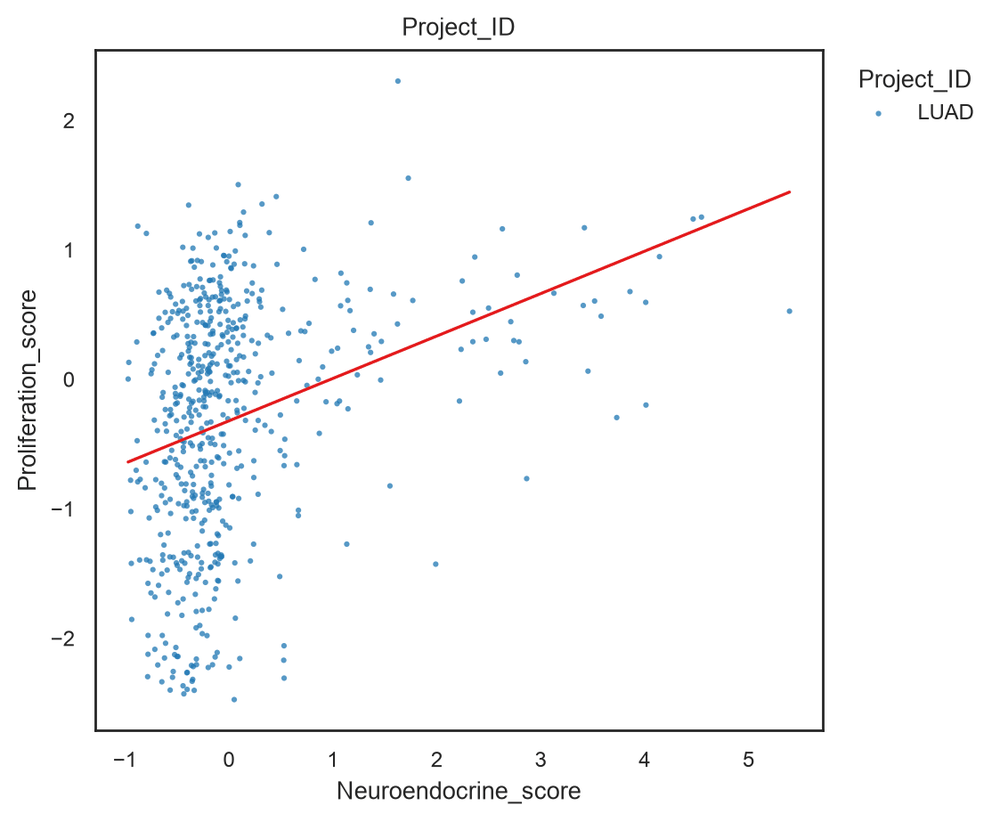

(<Figure size 1100x900 with 1 Axes>,
 array([<Axes: title={'center': 'Project_ID'}, xlabel='Neuroendocrine_score', ylabel='Proliferation_score'>],
       dtype=object),
 [{'n': 567,
   'pearson_r': 0.3170915552139395,
   'pearson_p': 1.0395590091281221e-14,
   'spearman_rho': 0.3579853022071705,
   'spearman_p': 1.3839045235866775e-18,
   'slope': 0.32758862496427565,
   'intercept': -0.32302816428708875}])

In [31]:
bk.pl.corrplot(
    adata_luad,
    x="Neuroendocrine_score",
    y="Proliferation_score",
    color="Project_ID",
    cmap="viridis",
    annotate=False,
    legend=True,
    point_size=5,
    #figsize=(3,2.5),
    save=FIGURES + "corr_plot_hue_example.png",
)

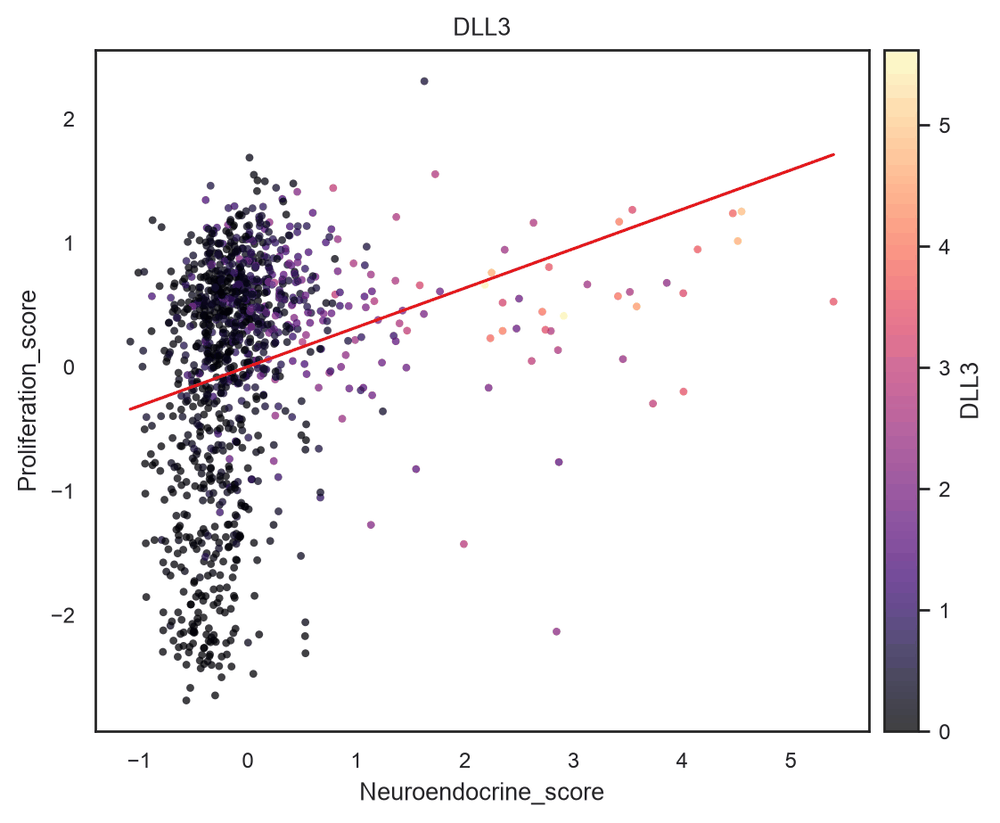

(<Figure size 1100x900 with 2 Axes>,
 array([<Axes: title={'center': 'DLL3'}, xlabel='Neuroendocrine_score', ylabel='Proliferation_score'>],
       dtype=object),
 [{'n': 1108,
   'pearson_r': 0.24720784406677243,
   'pearson_p': 6.863925694622921e-17,
   'spearman_rho': 0.34634652365866553,
   'spearman_p': 1.4079035810271415e-32,
   'slope': 0.31695792454056154,
   'intercept': 1.3439761519269638e-15}])

In [33]:
#Color by gene expression (continuous colormap)
bk.pl.corrplot(
    adata,
    x="Neuroendocrine_score",              # obs
    y="Proliferation_score",               # obs
    color="DLL3",                          # gene in adata.var_names
    layer="log1p_cpm",
    cmap="magma",
    point_size=10,
    annotate=False,
    #figsize=(3,2.5),
    save=FIGURES + "neuro_proliferation_DLL3.png",
)

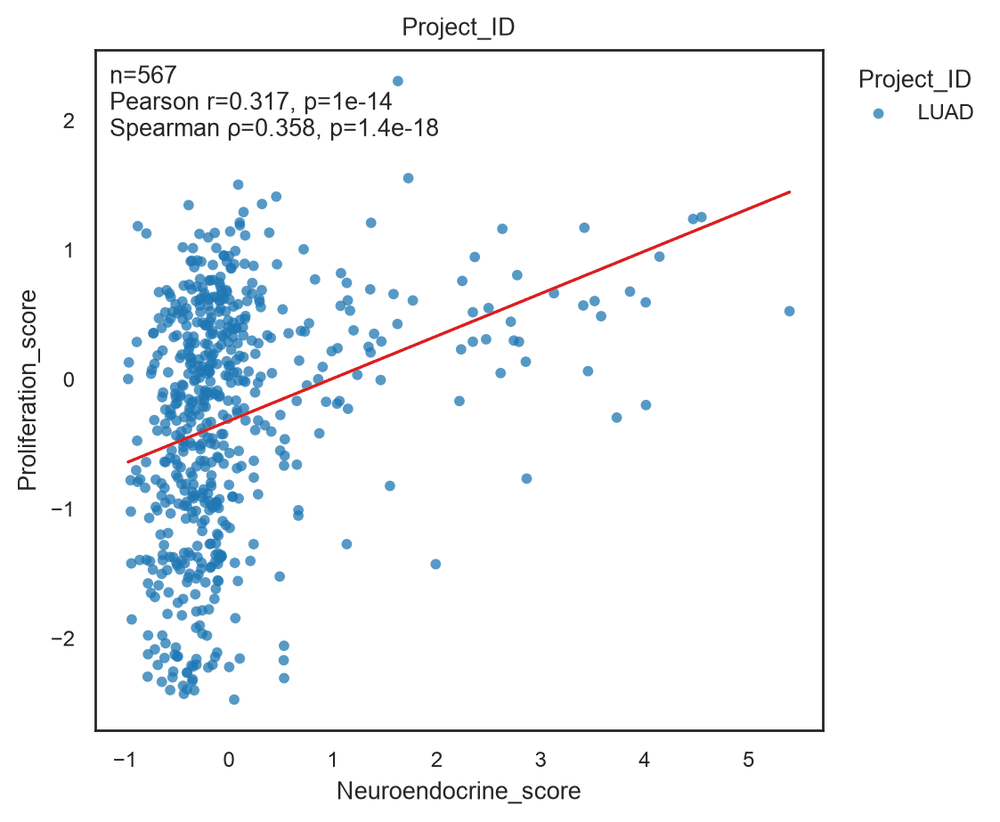

(<Figure size 1100x900 with 1 Axes>,
 array([<Axes: title={'center': 'Project_ID'}, xlabel='Neuroendocrine_score', ylabel='Proliferation_score'>],
       dtype=object),
 [{'n': 567,
   'pearson_r': 0.3170915552139395,
   'pearson_p': 1.0395590091281221e-14,
   'spearman_rho': 0.3579853022071705,
   'spearman_p': 1.3839045235866775e-18,
   'slope': 0.32758862496427565,
   'intercept': -0.32302816428708875}])

In [34]:
#Color by categorical metadata
bk.pl.corrplot(
    adata_luad,
    x="Neuroendocrine_score",
    y="Proliferation_score",
    color="Project_ID",
    palette="tab20",
)

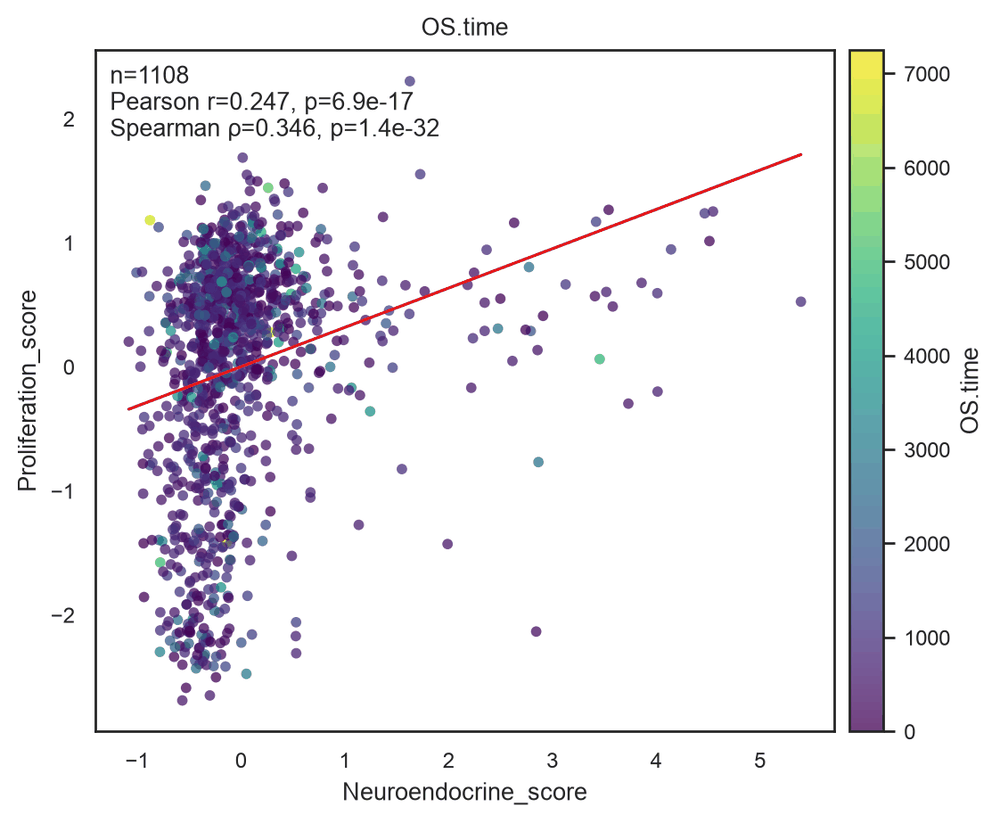

(<Figure size 1100x900 with 2 Axes>,
 array([<Axes: title={'center': 'OS.time'}, xlabel='Neuroendocrine_score', ylabel='Proliferation_score'>],
       dtype=object),
 [{'n': 1108,
   'pearson_r': 0.24720784406677243,
   'pearson_p': 6.863925694622921e-17,
   'spearman_rho': 0.34634652365866553,
   'spearman_p': 1.4079035810271415e-32,
   'slope': 0.31695792454056154,
   'intercept': 1.3439761519269638e-15}])

In [35]:
#Color by numerical metadata
bk.pl.corrplot(
    adata,
    x="Neuroendocrine_score",
    y="Proliferation_score",
    color="OS.time",
    cmap="viridis",
)

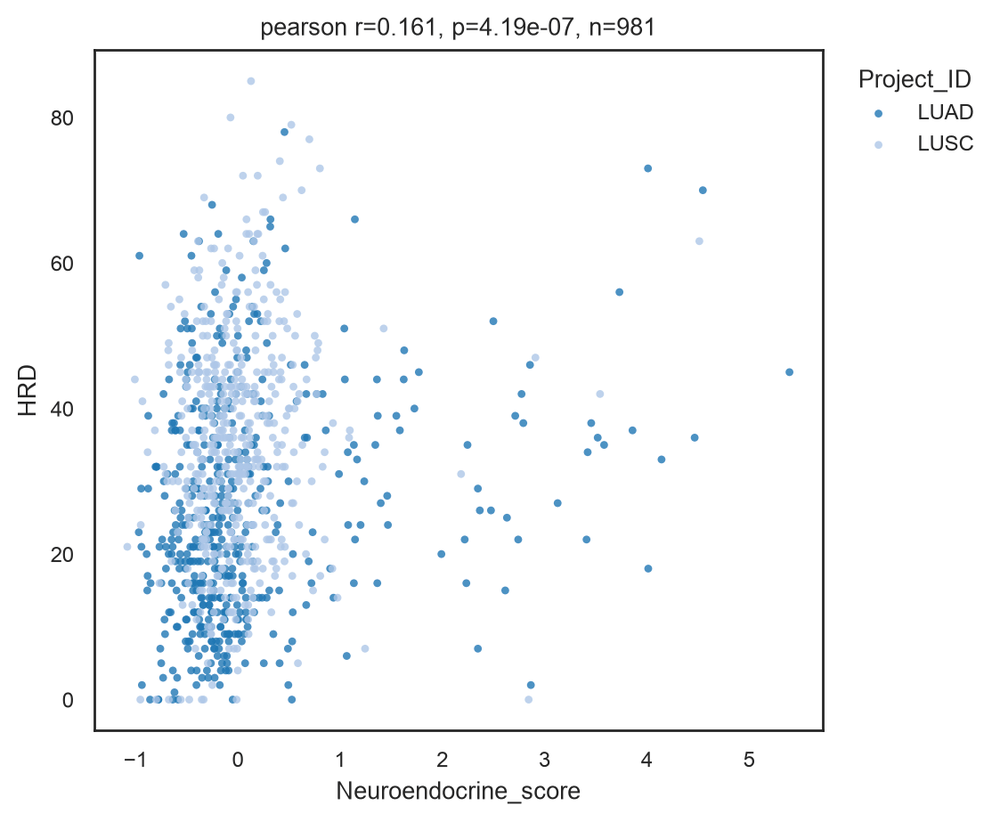

(<Figure size 1100x900 with 1 Axes>,
 <Axes: title={'center': 'pearson r=0.161, p=4.19e-07, n=981'}, xlabel='Neuroendocrine_score', ylabel='HRD'>)

In [37]:
bk.tl.plot_corr_scatter(
    adata,
    x="Neuroendocrine_score",
    y="HRD",                      # asbestos_exposure_age
    hue="Project_ID",                                 # categorical
    kind="obs_obs",                                  # "gene_obs" or "obs_obs"
    s=10,
    #figsize=(3,3),
)

#### Quick correlations without statistics

In [38]:
# Numeric obs vs numeric obs (top pairs)

selected_obs = ["Proliferation_score", "Neuroendocrine_score"]                  # single: "purity" or list: ["NE25_score", "purity"]

mat = bk.tl.obs_obs_corr_matrix(adata, focus=selected_obs)
mat.T.sort_values(by=selected_obs, ascending=False)

,Proliferation_score,Neuroendocrine_score
G2M_score,0.964595,0.237282
Module11_Prolif_score,0.962243,0.223677
GP1_Proliferation_DNA_repair,0.909519,0.239704
CSR_Activated_15701700,0.879371,0.255882
S_score,0.876834,0.220816
...,...,...
sample_type_id,-0.671944,-0.152468
samples.sample_type_id,-0.671944,-0.152468
GP7_Estrogen_signaling,-0.713047,-0.088772
MCD3_CD8_21214954,-0.753424,-0.177184


In [39]:
# Explicit focus × explicit against

focus=["NE25_score", "purity"]
against=["OS.time", "PFI.time", "DSS.time"]

mat = bk.tl.obs_obs_corr_matrix(adata, focus=focus, against=against,)
mat

,OS.time,PFI.time,DSS.time
NE25_score,-0.002713,0.000799,-0.002713
purity,0.037522,0.030437,0.037522


In [40]:
mat_first = mat.iloc[:,:20]

In [41]:
mat_first

,OS.time,PFI.time,DSS.time
NE25_score,-0.002713,0.000799,-0.002713
purity,0.037522,0.030437,0.037522


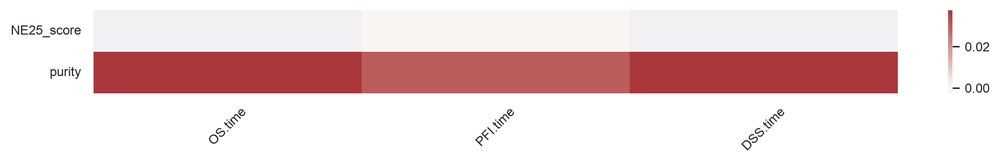

In [42]:
fig, ax = plt.subplots(figsize=(12,1))
sns.heatmap(mat_first, cmap="vlag", center=0,
           )
plt.xticks(rotation=45)
plt.show()

## 6.3. Associations with categorical data

Association functions answer a broader statistical question: “Is variable X statistically associated with variable Y?”  

They are:  
- Symmetric (not inherently DE)
- Exploratory
- Model-light
- Often non-parametric  

Association functions generalize beyond genes. They work for:  
- gene ↔ category
- numeric obs ↔ category
- gene ↔ gene
- numeric obs ↔ numeric obs
- category ↔ category  

They are closer to EDA / statistics than DE.

one single function.   
Practical advice (bulk RNA-seq).   
	•	Prefer Kruskal-Wallis over ANOVA (non-normal).  
	•	Always report effect size, not only p-values.    
	•	For clusters: ARI + Cramér’s V together is ideal.   
	•	Avoid Pearson with categorical encodings

### 6.3.1. Gene - categorical (screen genes associated with subtype)

In [43]:
dfg = bk.tl.gene_categorical_association(
    adata,
    genes=["DLL3", "SOX2", "CDC20"],
    groupby="Project_ID",
    layer="log1p_cpm",
    test="kruskal",                      # "auto", "kruskal", "anova"
    effect_size="epsilon2",              # "auto", "epsilon2", "eta2", "none"
)
dfg

,gene,groupby,n_groups,test,statistic,pval,effect,mean_LUAD,mean_LUSC,qval
0,SOX2,Project_ID,2,kruskal,338.820965,1.152510e-75,0.305444,1.865700,3.887139,3.457530e-75
1,CDC20,Project_ID,2,kruskal,189.765091,3.577724e-43,0.170674,2.665954,3.469905,5.366585e-43
2,DLL3,Project_ID,2,kruskal,12.741150,3.576977e-04,0.010616,0.564909,0.529728,3.576977e-04


In [44]:
columns = ["mean_LUAD", "mean_LUSC"]

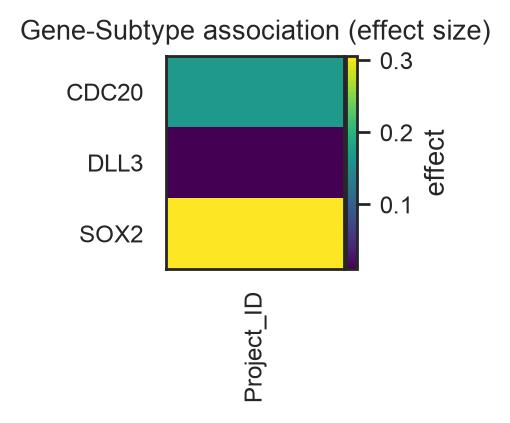

(<Figure size 400x400 with 2 Axes>,
 <Axes: title={'center': 'Gene-Subtype association (effect size)'}>)

In [47]:
#Plot a heatmap of effects:
bk.pl.association_heatmap(
    dfg,
    index="gene",
    columns="groupby",
    values="effect",
    title="Gene-Subtype association (effect size)",
    figsize=(2,2),
    save=FIGURES + "gene_association_heatmap.png",
)

#### bk.pl.gene_association()  
- automatic post-hoc (MWU + BH) and bracket annotation
- new effect-size aware volcano for categorical associations

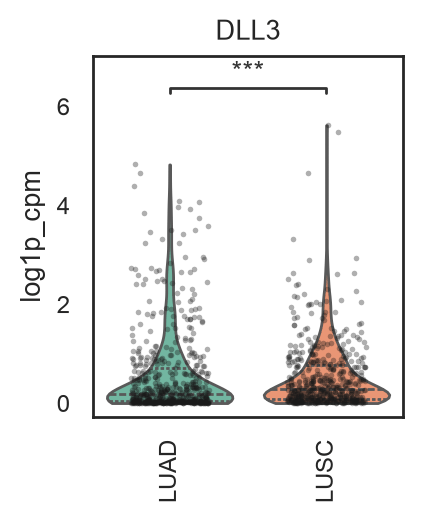

(<Figure size 400x500 with 1 Axes>,
 array([<Axes: title={'center': 'DLL3'}, ylabel='log1p_cpm'>], dtype=object))

In [48]:
bk.pl.gene_association(
    adata,
    gene=["DLL3"],
    groupby="Project_ID",
    layer="log1p_cpm",
    rotate_xticklabels=90,
    annotate_posthoc=True,
    figsize=(2,2.5),
    save=FIGURES + "gene_association_DLL3_lung.png",
)

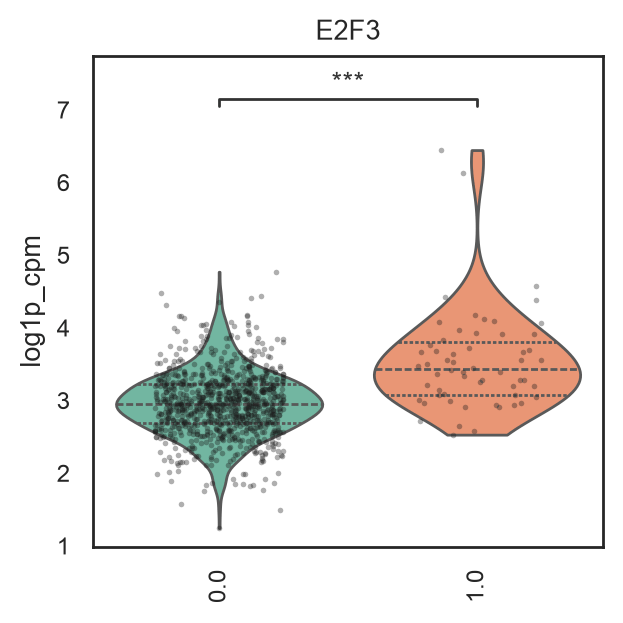

(<Figure size 600x600 with 1 Axes>,
 array([<Axes: title={'center': 'E2F3'}, ylabel='log1p_cpm'>], dtype=object))

In [50]:
bk.pl.gene_association(
    adata,
    gene=["E2F3"],
    groupby="RB1_mut",
    layer="log1p_cpm",
    rotate_xticklabels=90,
    annotate_posthoc=True,
    figsize=(3,3),
    save=FIGURES + "gene_association_E2F3_RB1_mutant.png",
)

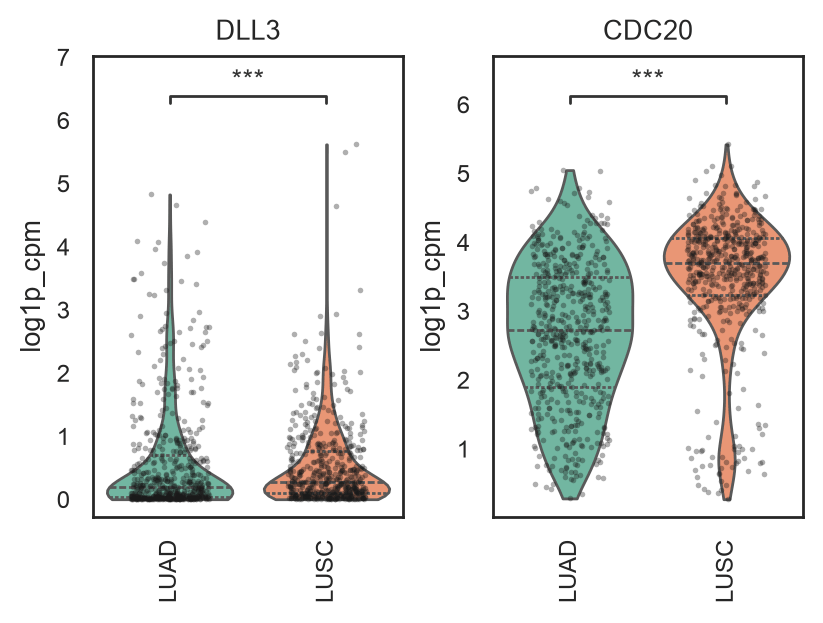

(<Figure size 800x600 with 2 Axes>,
 array([<Axes: title={'center': 'DLL3'}, ylabel='log1p_cpm'>,
        <Axes: title={'center': 'CDC20'}, ylabel='log1p_cpm'>],
       dtype=object))

In [51]:
# Multiple genes (row of panels)
bk.pl.gene_association(
    adata,
    gene=["DLL3", "CDC20"],
    groupby="Project_ID",
    layer="log1p_cpm",
    rotate_xticklabels=90,
    figsize=(4, 3),  # per-panel size; total width = 3*4.0
    save=FIGURES + "associations_DLL3_CDC20_ProjectID.png",
)

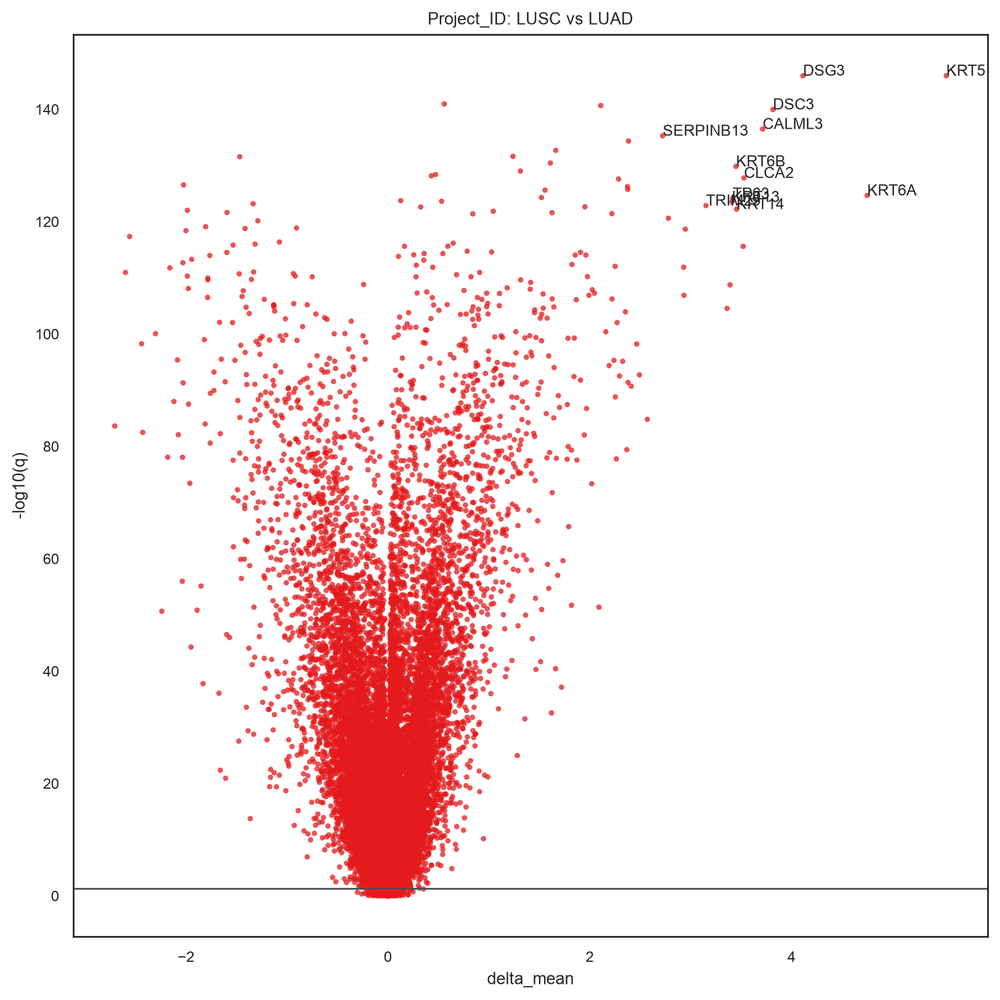

In [52]:
fig, ax, df = bk.pl.gene_association_volcano(
    adata,
    groupby="Project_ID",
    group="LUSC",
    reference="LUAD",   # or None for "rest"
    layer="log1p_cpm",
    alpha=0.05,
    figsize=(8,8),
    save=FIGURES + "assoc_volcano_SCLC_vs_LUAD.png",
)

Gene - categorical and rankplots

In [53]:
df = bk.tl.gene_categorical_association(
    adata,
    genes=["RB1", "TP53", "CCND1"],                 # All genes if None. Select one gene or a list of genes
    groupby="Project_ID",
    layer="log1p_cpm",
    test="kruskal",
    effect_size="epsilon2",
)
df

,gene,groupby,n_groups,test,statistic,pval,effect,mean_LUAD,mean_LUSC,qval
0,RB1,Project_ID,2,kruskal,76.765019,1.925583e-18,0.068504,3.398147,3.596113,5.776749e-18
1,CCND1,Project_ID,2,kruskal,58.929368,1.634346e-14,0.052377,5.062222,4.698303,2.451519e-14
2,TP53,Project_ID,2,kruskal,1.801087,1.795812e-01,0.000724,3.619411,3.644798,1.795812e-01


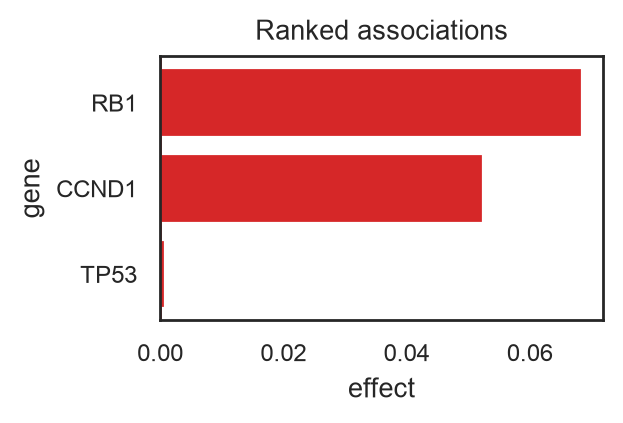

(<Figure size 600x400 with 1 Axes>,
 <Axes: title={'center': 'Ranked associations'}, xlabel='effect', ylabel='gene'>)

In [54]:
bk.pl.rankplot_association(res=df, gene_col="gene", effect_col="effect", sort_by="qval", n_items=30,
                          figsize=(3,2), save=FIGURES + "rankplot_association_example.png")

In [8]:
df1 = bk.tl.gene_categorical_association(adata, genes=["DLL3","SOX2"], groupby="Project_ID")
df2 = bk.tl.gene_categorical_association(adata, genes=["DLL3","SOX2"], groupby="Gender")

df_all = pd.concat([df1, df2], ignore_index=True)
df_all

,gene,groupby,n_groups,test,statistic,pval,effect,mean_LUAD,mean_LUSC,qval,mean_Female,mean_Male
0,SOX2,Project_ID,2,kruskal,338.820965,1.152510e-75,0.305444,1.865700,3.887139,2.305020e-75,NaN,NaN
1,DLL3,Project_ID,2,kruskal,12.741150,3.576977e-04,0.010616,0.564909,0.529728,3.576977e-04,NaN,NaN
2,SOX2,Gender,2,kruskal,41.001334,1.521254e-10,0.036766,NaN,NaN,3.042508e-10,2.415804,3.142529
3,DLL3,Gender,2,kruskal,6.897741,8.630473e-03,0.005421,NaN,NaN,8.630473e-03,0.492663,0.586205


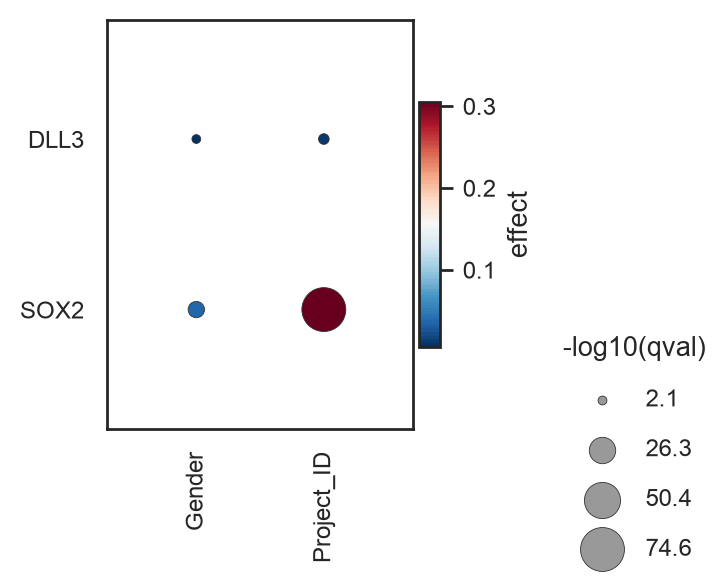

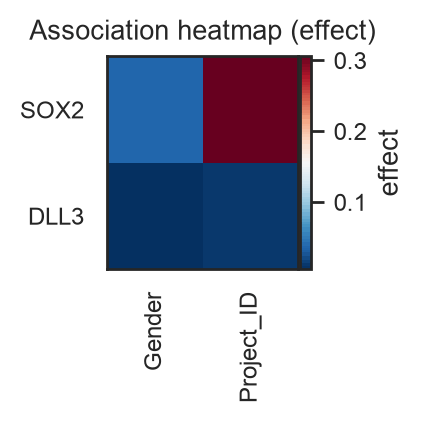

(<Figure size 400x400 with 2 Axes>,
 <Axes: title={'center': 'Association heatmap (effect)'}>)

In [9]:
bk.pl.dotplot_association(df_all, feature_col="gene", groupby_col="groupby", top_n=50,
                         figsize=(2,2))
bk.pl.heatmap_association(df_all, feature_col="gene", groupby_col="groupby", value_col="effect", top_n=40,
                         figsize=(2,2))

#### A) Rank genes associated with a category (associations, not DE)

In [10]:
res = bk.tl.store_rank_genes_groups_fast(
    adata,
    groupby="Project_ID",
    group="LUSC",
    reference="rest",
    layer="log1p_cpm",
    method="mwu",
    subkey="assoc:Project_ID:LUSC_vs_rest",
)
res.head()

,gene,groupby,group,reference,effect,pval,qval,mean_group,mean_ref,median_group,median_ref
0,DSG3,Project_ID,LUSC,rest,4.115148,6.990034e-151,1.114596e-146,4.378563,0.263415,5.123014,0.042745
1,KRT5,Project_ID,LUSC,rest,5.534623,3.688628e-151,1.114596e-146,6.897567,1.362944,7.885148,0.969376
2,KRT74,Project_ID,LUSC,rest,0.559892,1.095072e-145,1.164098e-141,0.568832,0.008940,0.430747,0.000000
3,CERS3,Project_ID,LUSC,rest,2.109679,2.856131e-145,2.277122e-141,2.183057,0.073379,2.553165,0.019474
4,DSC3,Project_ID,LUSC,rest,3.816930,1.776803e-144,1.133281e-140,4.443148,0.626218,5.129488,0.327618


In [11]:
res

,gene,groupby,group,reference,effect,pval,qval,mean_group,mean_ref,median_group,median_ref
0,DSG3,Project_ID,LUSC,rest,4.115148,6.990034e-151,1.114596e-146,4.378563,0.263415,5.123014,0.042745
1,KRT5,Project_ID,LUSC,rest,5.534623,3.688628e-151,1.114596e-146,6.897567,1.362944,7.885148,0.969376
2,KRT74,Project_ID,LUSC,rest,0.559892,1.095072e-145,1.164098e-141,0.568832,0.008940,0.430747,0.000000
3,CERS3,Project_ID,LUSC,rest,2.109679,2.856131e-145,2.277122e-141,2.183057,0.073379,2.553165,0.019474
4,DSC3,Project_ID,LUSC,rest,3.816930,1.776803e-144,1.133281e-140,4.443148,0.626218,5.129488,0.327618
...,...,...,...,...,...,...,...,...,...,...,...
31886,ENSG00000267268.1,Project_ID,LUSC,rest,0.002513,9.993073e-01,9.994327e-01,0.029247,0.026734,0.012437,0.014525
31887,IGHV7-27,Project_ID,LUSC,rest,0.014658,9.993996e-01,9.994633e-01,0.157745,0.143086,0.073242,0.069457
31888,SNX1,Project_ID,LUSC,rest,-0.002329,9.994006e-01,9.994633e-01,4.278006,4.280335,4.262963,4.253952
31889,ENSG00000270591.1,Project_ID,LUSC,rest,-0.001767,9.996998e-01,9.997311e-01,0.040839,0.042606,0.033141,0.031438


#### B) Volcano plot (effect-size aware)

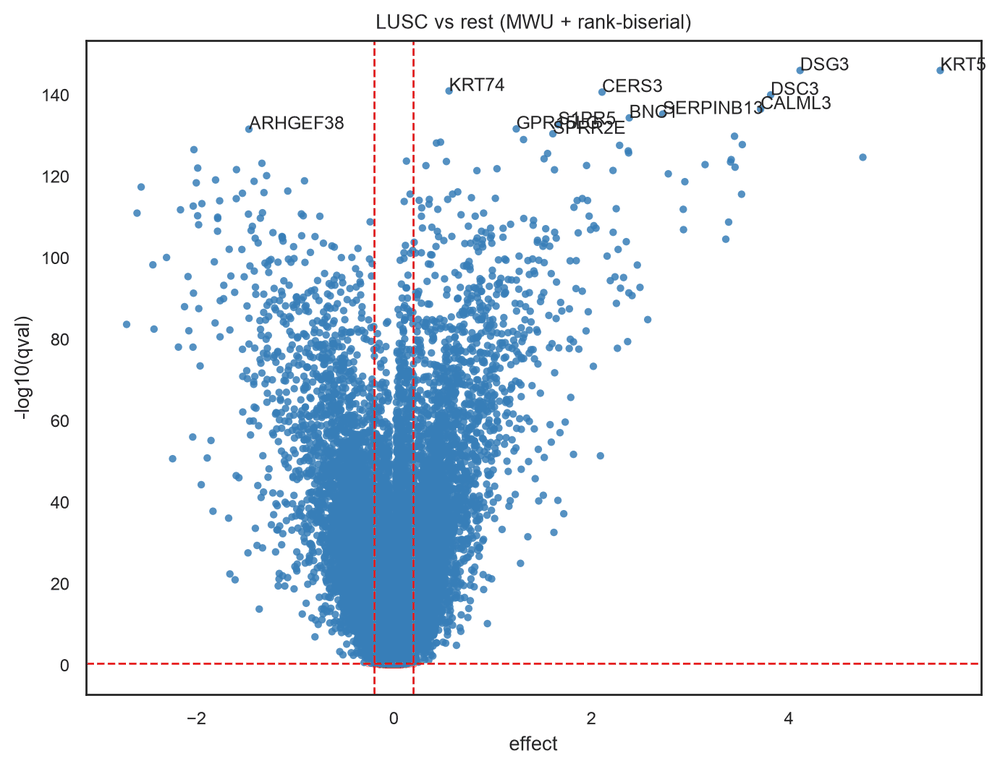

(<Figure size 1360x1040 with 1 Axes>,
 <Axes: title={'center': 'LUSC vs rest (MWU + rank-biserial)'}, xlabel='effect', ylabel='-log10(qval)'>)

In [12]:
bk.pl.volcano_categorical(
    res,
    x="effect",   # "effect_size" or x="log2FC"
    q_thr=0.5,
    effect_thr=0.2,
    title="LUSC vs rest (MWU + rank-biserial)",
    #save="figs/volcano_ACC.png",
)

#### D) Automatic posthoc per gene

In [13]:
posthoc = {
    g: bk.tl.posthoc_per_gene(
        adata,
        gene=g,
        groupby="Project_ID",
        layer="log1p_cpm",
        method="mwu",
    )
    for g in ["DLL3", "SOX11", "CDC20"]
}
posthoc["DLL3"].head()


,gene,group1,group2,effect,pval,qval
0,DLL3,LUAD,LUSC,0.035181,0.000358,0.000358


### 6.3.2. Numeric obs & categorical (which metadata differs across clusters)

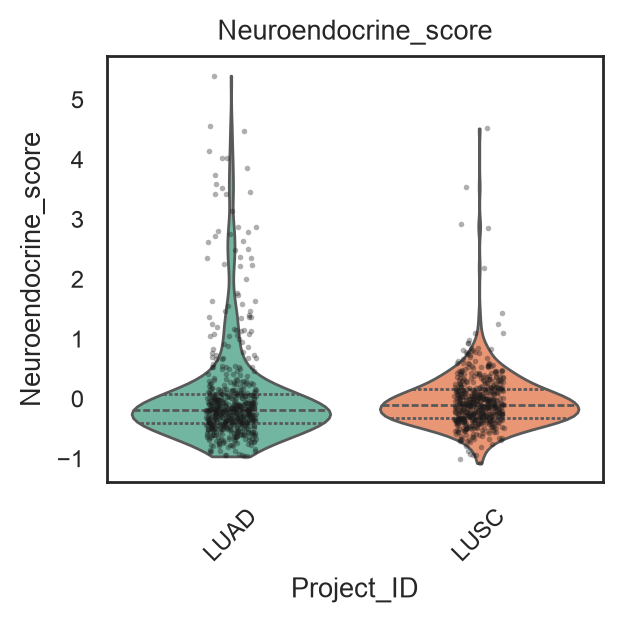

(<Figure size 600x600 with 1 Axes>,
 array([<Axes: title={'center': 'Neuroendocrine_score'}, xlabel='Project_ID', ylabel='Neuroendocrine_score'>],
       dtype=object))

In [15]:
# without statistics
bk.pl.violin(adata, keys=["Neuroendocrine_score"], groupby="Project_ID",figsize=(3,3),
            save=FIGURES + "violin_groups_example.png"
            )

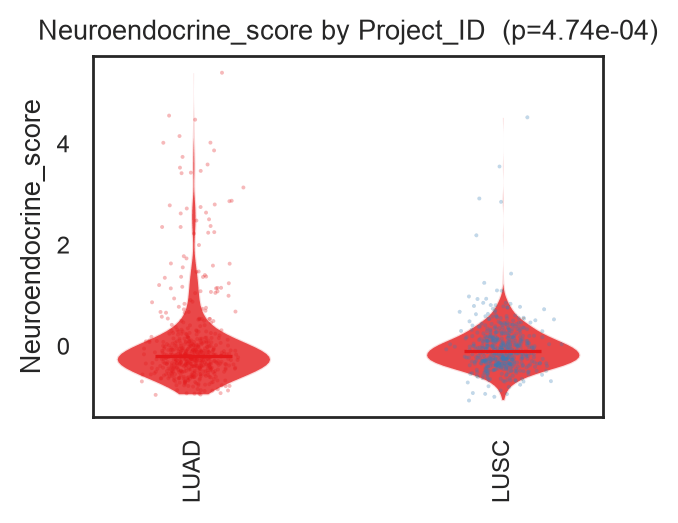

(<Figure size 600x500 with 1 Axes>,
 <Axes: title={'center': 'Neuroendocrine_score by Project_ID  (p=4.74e-04)'}, ylabel='Neuroendocrine_score'>)

In [16]:
#Plot one variable with a p-value:
bk.pl.boxplot_with_stats(
    adata,
    y="Neuroendocrine_score",
    groupby="Project_ID",
    kind="violin",                        # "box" or "violin"
    figsize=(3, 2.5),
    save=FIGURES + "boxplot_stats_example.png",
)

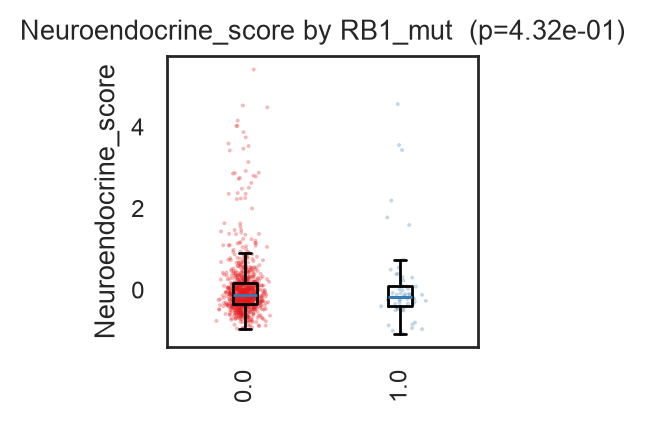

(<Figure size 400x400 with 1 Axes>,
 <Axes: title={'center': 'Neuroendocrine_score by RB1_mut  (p=4.32e-01)'}, ylabel='Neuroendocrine_score'>)

In [17]:
#Plot one variable with a p-value:
bk.pl.boxplot_with_stats(
    adata,
    y="Neuroendocrine_score",
    groupby="RB1_mut",
    kind="box",
    figsize=(2, 2),
    save=FIGURES + "boxplot_stats_example.png",
)

In [18]:
dfo = bk.tl.obs_categorical_association(
    adata,
    obs_keys=["Neuroendocrine_score"],                   # all numeric obs
    groupby="RB1_mut",
    method="kruskal",
)
dfo.head(20)

,obs,groupby,n_groups,test,statistic,pval,effect,mean_0.0,mean_1.0,qval
0,Neuroendocrine_score,RB1_mut,2,kruskal,0.617704,0.431902,-0.000395,0.029609,0.095866,0.431902


#### A) Rank genes associated with a category (associations, not DE)

In [19]:
# for numeric obs
y = pd.DataFrame({"y": adata.obs["purity"], "grp": adata.obs["Project_ID"]})
post = bk.tl.pairwise_posthoc(y, method="mwu")

In [20]:
post

,group1,group2,n1,n2,pval,effect,delta_mean,delta_median,qval
0,LUAD,LUSC,496,485,0.000027,0.154922,-0.049971,-0.05,0.000027


In [21]:
dfo = bk.tl.obs_categorical_association(
    adata,
    groupby="Project_ID",
    obs_keys=["purity", "NE25_score"],
    method="kruskal",
)
dfo

,obs,groupby,n_groups,test,statistic,pval,effect,mean_LUAD,mean_LUSC,qval
0,purity,Project_ID,2,kruskal,17.643276,0.000027,0.017000,0.462359,0.512330,0.000053
1,NE25_score,Project_ID,2,kruskal,0.171742,0.678568,-0.000749,0.004937,-0.024153,0.678568


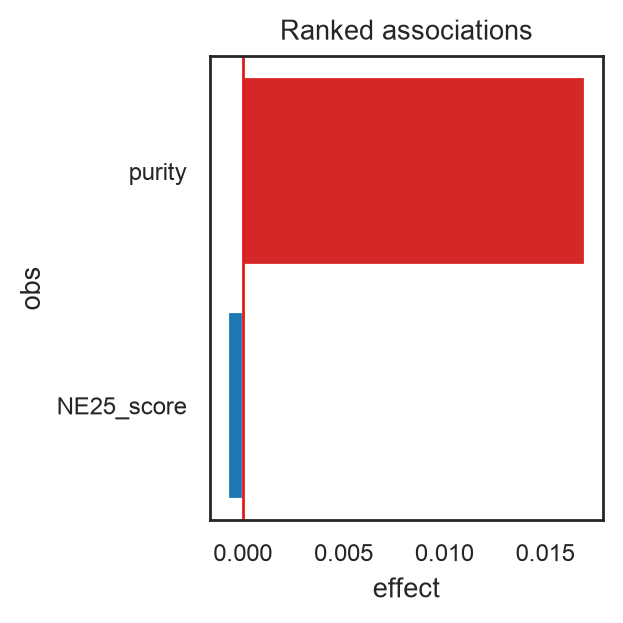

(<Figure size 600x600 with 1 Axes>,
 <Axes: title={'center': 'Ranked associations'}, xlabel='effect', ylabel='obs'>)

In [23]:
bk.pl.rankplot_association(
    res=dfo,
    gene_col="obs",
    effect_col="effect",
    sort_by="qval",
    n_items=20,
    figsize=(3,3),
)


In [24]:
res = bk.tl.store_rank_genes_groups_fast(
    adata,
    groupby="Project_ID",
    group="LUSC",
    reference="rest",
    layer="log1p_cpm",
    method="mwu",
    subkey="assoc:Project_ID:LUSC_vs_rest",
)
res.head()

,gene,groupby,group,reference,effect,pval,qval,mean_group,mean_ref,median_group,median_ref
0,DSG3,Project_ID,LUSC,rest,4.115148,6.990034e-151,1.114596e-146,4.378563,0.263415,5.123014,0.042745
1,KRT5,Project_ID,LUSC,rest,5.534623,3.688628e-151,1.114596e-146,6.897567,1.362944,7.885148,0.969376
2,KRT74,Project_ID,LUSC,rest,0.559892,1.095072e-145,1.164098e-141,0.568832,0.008940,0.430747,0.000000
3,CERS3,Project_ID,LUSC,rest,2.109679,2.856131e-145,2.277122e-141,2.183057,0.073379,2.553165,0.019474
4,DSC3,Project_ID,LUSC,rest,3.816930,1.776803e-144,1.133281e-140,4.443148,0.626218,5.129488,0.327618


### 6.3.3. Associations between categorical data

In [25]:
dict_assoc = bk.tl.categorical_association(
    adata,
    key1="Project_ID",                   # all numeric obs
    key2="RB1_mut",
)

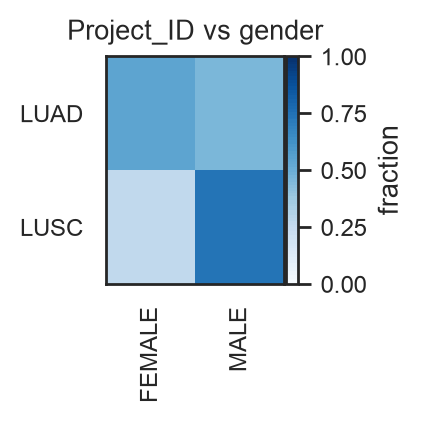

(<Figure size 400x400 with 2 Axes>,
 <Axes: title={'center': 'Project_ID vs gender'}>,
 {'key1': 'Project_ID',
  'key2': 'gender',
  'normalize': 'row',
  'table': gender      FEMALE  MALE
  Project_ID              
  LUAD           306   261
  LUSC           142   399,
  'matrix': array([[0.53968254, 0.46031746],
         [0.26247689, 0.73752311]]),
  'metrics': {'key1': 'Project_ID',
   'key2': 'gender',
   'chi2': 87.18157965681547,
   'dof': 1,
   'pval': 9.90015701639614e-21,
   'expected': array([[229.25631769, 337.74368231],
          [218.74368231, 322.25631769]])}})

In [26]:
# uses bk.tl.categorical_association()
bk.pl.categorical_confusion(
    adata,
    key1="Project_ID",
    key2="gender",
    normalize="row",
    cmap="Blues",
    figsize=(2,2),
    save=FIGURES + "cat_confusion.png",
)

# 7. General Plots 
<a id="plots"></a>

## 7.1. Dotplot

In [27]:
# Check if genes have zeros (e.g. Fraction of samples expressing is not 1)

genes = ["CDK1","MKI67","CD3E","CD79A","MS4A1"]
gidx = [adata.var_names.get_loc(g) for g in genes]
X = adata.layers["counts"][:, gidx]
X = X.toarray() if hasattr(X, "toarray") else np.asarray(X)

print("fraction >0 per gene:", (X > 0).mean(axis=0))
print("min/max counts per gene:", X.min(axis=0), X.max(axis=0))

fraction >0 per gene: [1.         1.         1.         1.         0.99548736]
min/max counts per gene: [84 86 17  7  0] [16002 45741 10670 34355 48037]


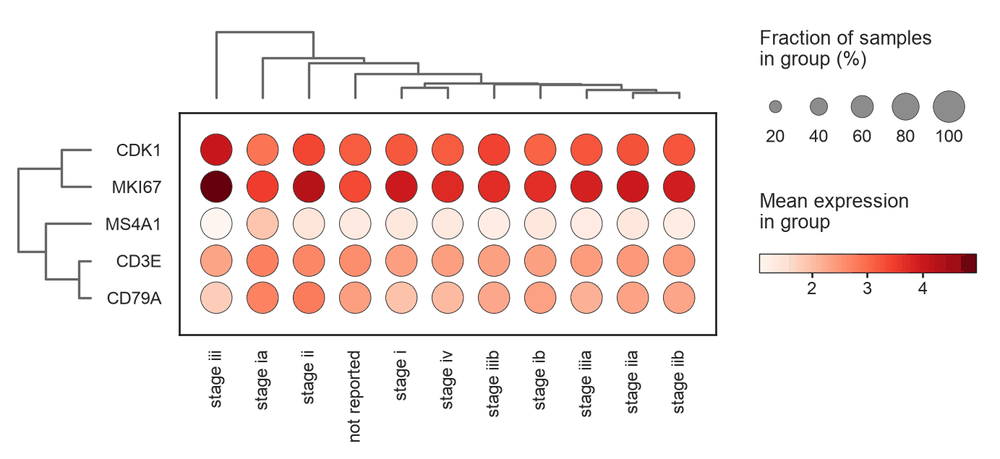

(<Figure size 1343.92x595.2 with 5 Axes>, <Axes: >)

In [28]:
bk.pl.dotplot(
    adata,
    var_names=["CDK1","MKI67","CD3E","CD79A","MS4A1"],
    groupby="diagnoses.tumor_stage",
    swap_axes=True,
    row_spacing = 0.8,
    dendrogram_top=True,
    dendrogram_rows=True,
    row_dendrogram_position="outer_left",
    title=None,
)

In [29]:
markers = {
    "B-cell": ["CD79A","MS4A1"],
    "Dendritic": ["FCER1A"],
    "Monocytes": ["CST3","FCGR3A"],
    "NK": ["GNLY","NKG7"],
    "Other": ["IGLL1"],
    "T-cell": ["CD3D"],
}

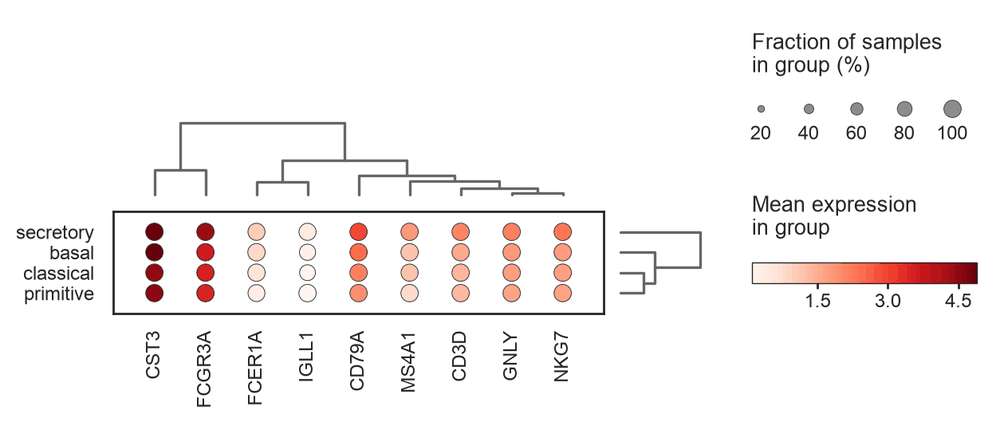

(<Figure size 1214.16x494.227 with 5 Axes>, <Axes: >)

In [30]:
#var_groups dict (Scanpy-like brackets + ordering)

bk.pl.dotplot(
    adata,
    var_groups=markers,
    groupby="Subtype_mRNA",
    swap_axes=False,
    row_spacing = 0.4,
    dendrogram_rows=True,  # cluster groups
    dendrogram_top=True,  # cluster genes within the full list (still keeps brackets)
    save="figs/dotplot_scanpy_like.png",
)

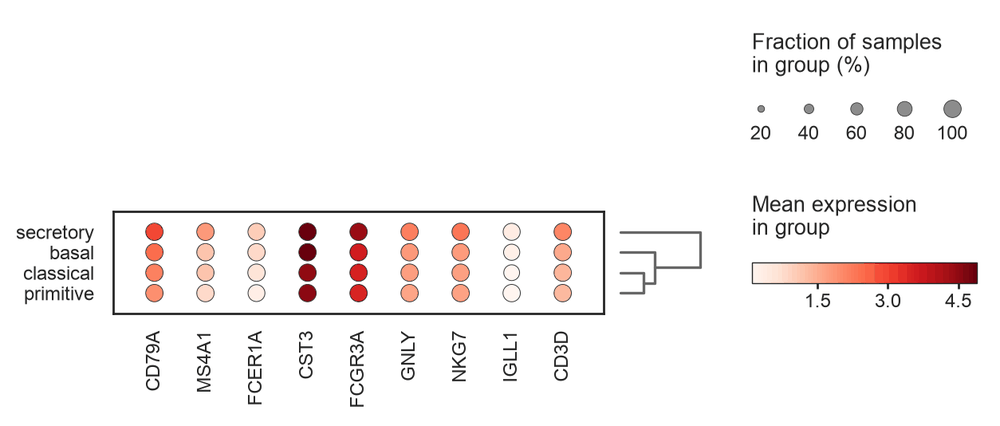

(<Figure size 1214.16x494.227 with 4 Axes>, <Axes: >)

In [31]:
bk.pl.dotplot(
    adata,
    var_groups=markers,
    groupby="Subtype_mRNA",
    swap_axes=False,
    row_spacing = 0.4,
    dendrogram_rows=True,  # cluster groups
    dendrogram_top=False,  # cluster genes within the full list (still keeps brackets)
    save="figs/dotplot_scanpy_like.png",
)

## 7.3. Violin plot

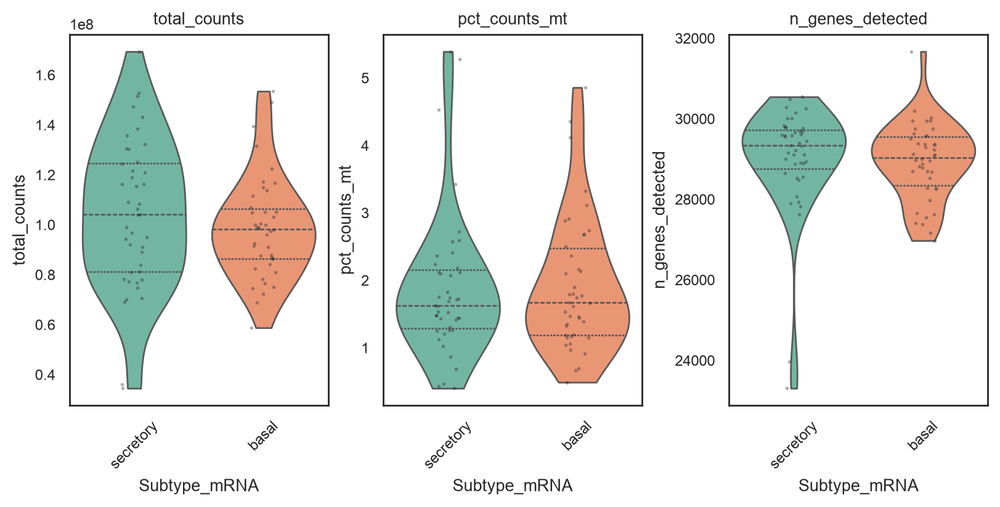

(<Figure size 1600x800 with 3 Axes>,
 array([<Axes: title={'center': 'total_counts'}, xlabel='Subtype_mRNA', ylabel='total_counts'>,
        <Axes: title={'center': 'pct_counts_mt'}, xlabel='Subtype_mRNA', ylabel='pct_counts_mt'>,
        <Axes: title={'center': 'n_genes_detected'}, xlabel='Subtype_mRNA', ylabel='n_genes_detected'>],
       dtype=object))

In [32]:
bk.pl.violin(
    adata,
    keys=["total_counts", "pct_counts_mt", "n_genes_detected"],
    groupby="Subtype_mRNA",
    order=["secretory", "basal"],
    #figsize=(6, 3),
    save=FIGURES + "violin_qc.png",
)

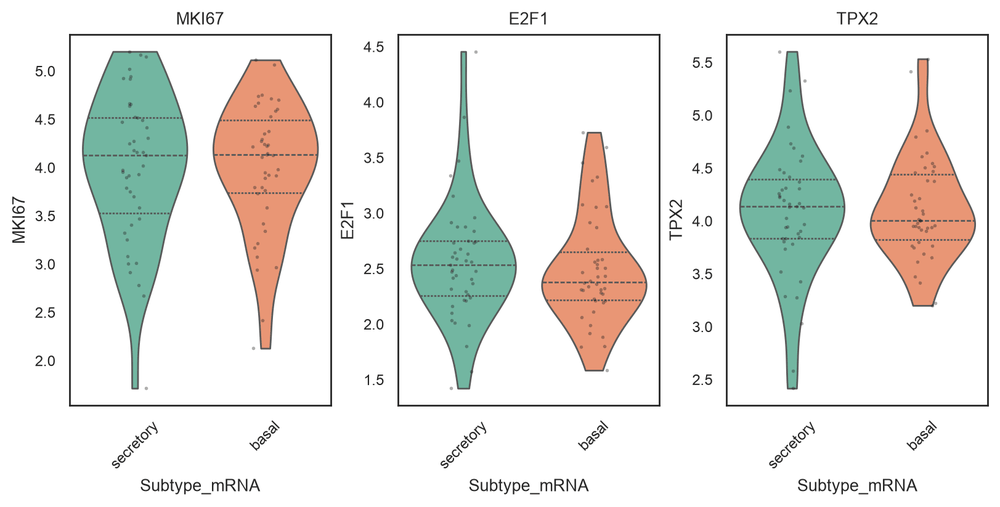

(<Figure size 1600x800 with 3 Axes>,
 array([<Axes: title={'center': 'MKI67'}, xlabel='Subtype_mRNA', ylabel='MKI67'>,
        <Axes: title={'center': 'E2F1'}, xlabel='Subtype_mRNA', ylabel='E2F1'>,
        <Axes: title={'center': 'TPX2'}, xlabel='Subtype_mRNA', ylabel='TPX2'>],
       dtype=object))

In [33]:
bk.pl.violin(adata, keys=["MKI67","E2F1", "TPX2"], groupby="Subtype_mRNA", 
                   order=["secretory", "basal"],
                   layer="log1p_cpm",
                   #figsize=(3, 4),
                   save=FIGURES + "violin_genes.png")

## 7.4. Violin Gene Plot

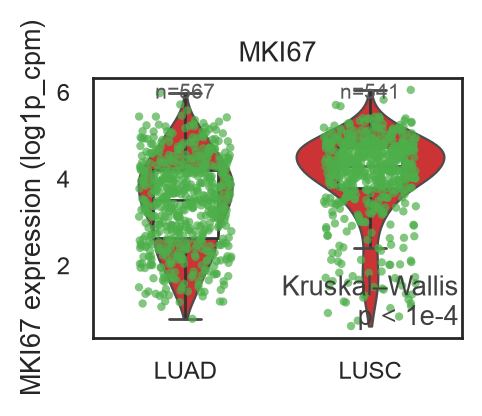

(<Figure size 500x400 with 1 Axes>,
 <Axes: title={'center': 'MKI67'}, ylabel='MKI67 expression (log1p_cpm)'>,
 {'test': 'Kruskal–Wallis', 'pvalue': 3.8429482902849554e-30, 'compare': None})

In [34]:
bk.pl.gene_plot(
    adata,
    gene="MKI67",
    groupby="Project_ID",
    layer="log1p_cpm",
    test="auto",           # defaults to Kruskal
    kind="both",
    figsize=(2.5,2),
    save=FIGURES + "MKI67_by_lung.png",
)

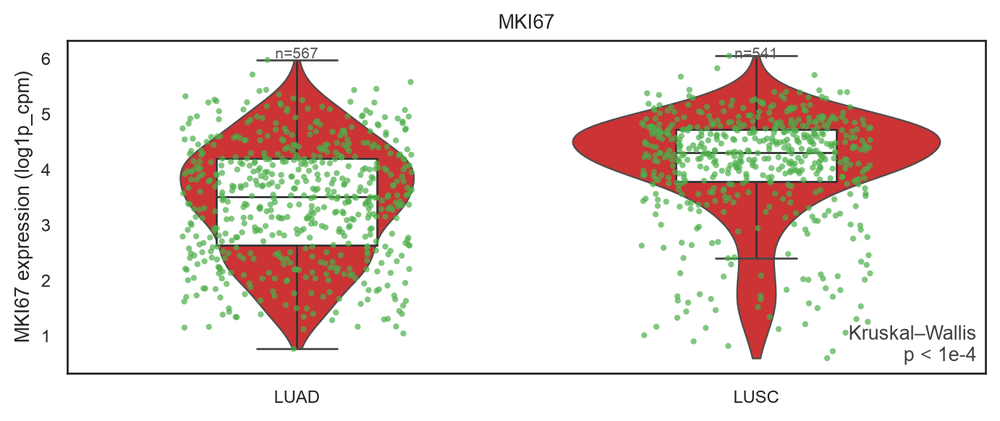

(<Figure size 1400x600 with 1 Axes>,
 <Axes: title={'center': 'MKI67'}, ylabel='MKI67 expression (log1p_cpm)'>,
 {'test': 'Kruskal–Wallis', 'pvalue': 3.8429482902849554e-30, 'compare': None})

In [35]:
bk.pl.gene_plot(
    adata,
    gene="MKI67",
    groupby="Project_ID",
    layer="log1p_cpm",
    test="auto",           # defaults to Kruskal
    kind="both",
    figsize=(7,3),
    save=FIGURES + "MKI67_by_lung.png",
)

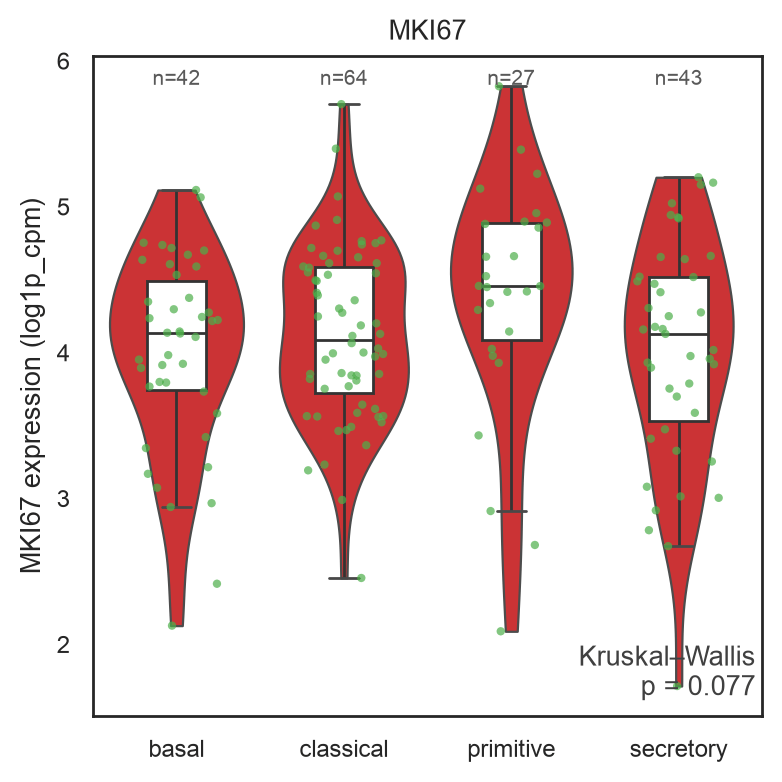

(<Figure size 800x800 with 1 Axes>,
 <Axes: title={'center': 'MKI67'}, ylabel='MKI67 expression (log1p_cpm)'>,
 {'test': 'Kruskal–Wallis', 'pvalue': 0.07696587880234473, 'compare': None})

In [36]:
# Overall p-value across all subtypes
bk.pl.gene_plot(
    adata,
    gene="MKI67",
    groupby="Subtype_mRNA",
    layer="log1p_cpm",
    test="auto",           # defaults to Kruskal
    kind="both",
    figsize=(4,4),
    save=FIGURES + "CDK1_by_PAM50.png",
)

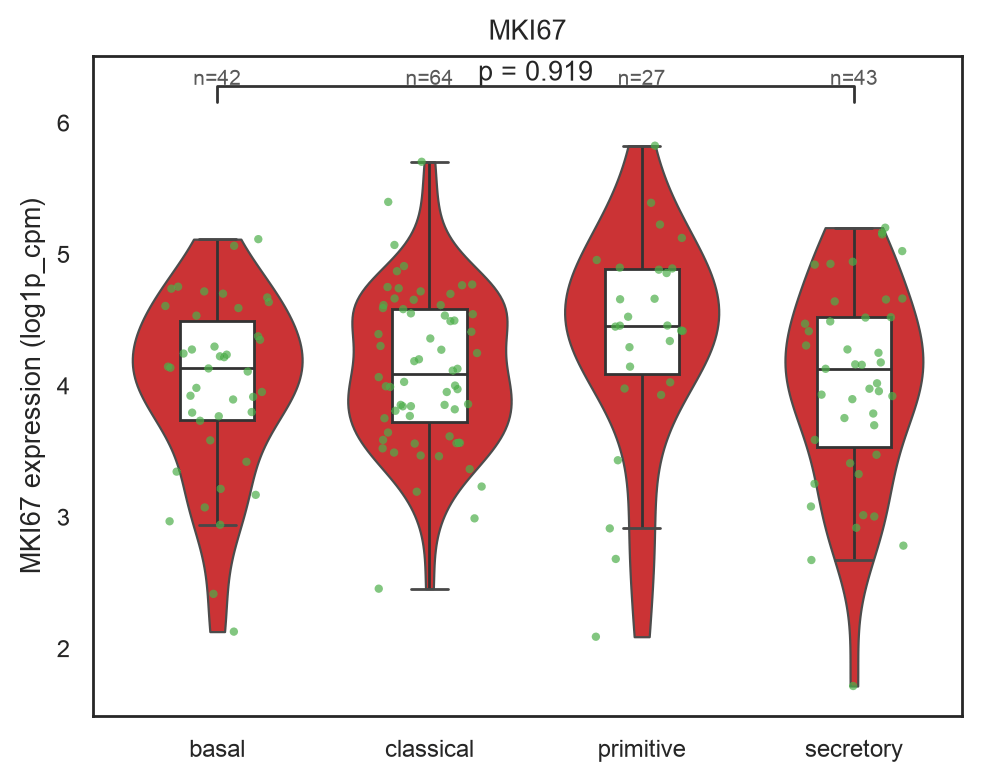

(<Figure size 1000x800 with 1 Axes>,
 <Axes: title={'center': 'MKI67'}, ylabel='MKI67 expression (log1p_cpm)'>,
 {'test': 'Mann–Whitney U',
  'pvalue': 0.9194841586973252,
  'compare': ['secretory', 'basal']})

In [37]:
# Pairwise with bracket
bk.pl.gene_plot(
    adata,
    gene="MKI67",
    groupby="Subtype_mRNA",
    layer="log1p_cpm",
    compare=["secretory", "basal"],
    test="wilcoxon",       # Mann–Whitney U
    kind="both",
    figsize=(5,4),
    save=FIGURES + "MKI67_LumA_vs_LumB.png",
)

## 7.5. Sample distances

A) Sample distances (Euclidean on log1p_cpm) + metadata colors

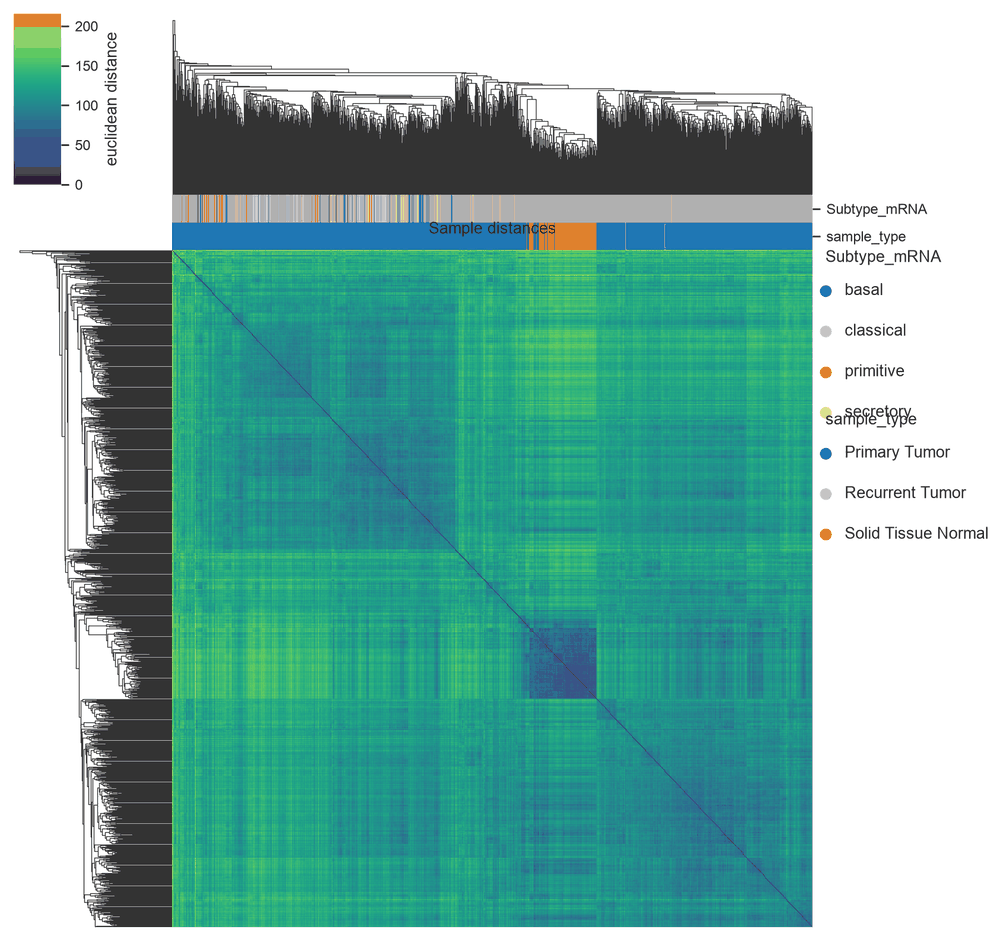

In [40]:
bk.pl.sample_distances(
    adata,
    layer="log1p_cpm",
    metric="euclidean",
    method="average",
    col_colors=["Subtype_mRNA", "sample_type"],
    show_labels=False,
    figsize=(8,8),
    save=FIGURES + "sample_distances.png",
)

B) Sample correlation clustergram (recommended for bulk QC)

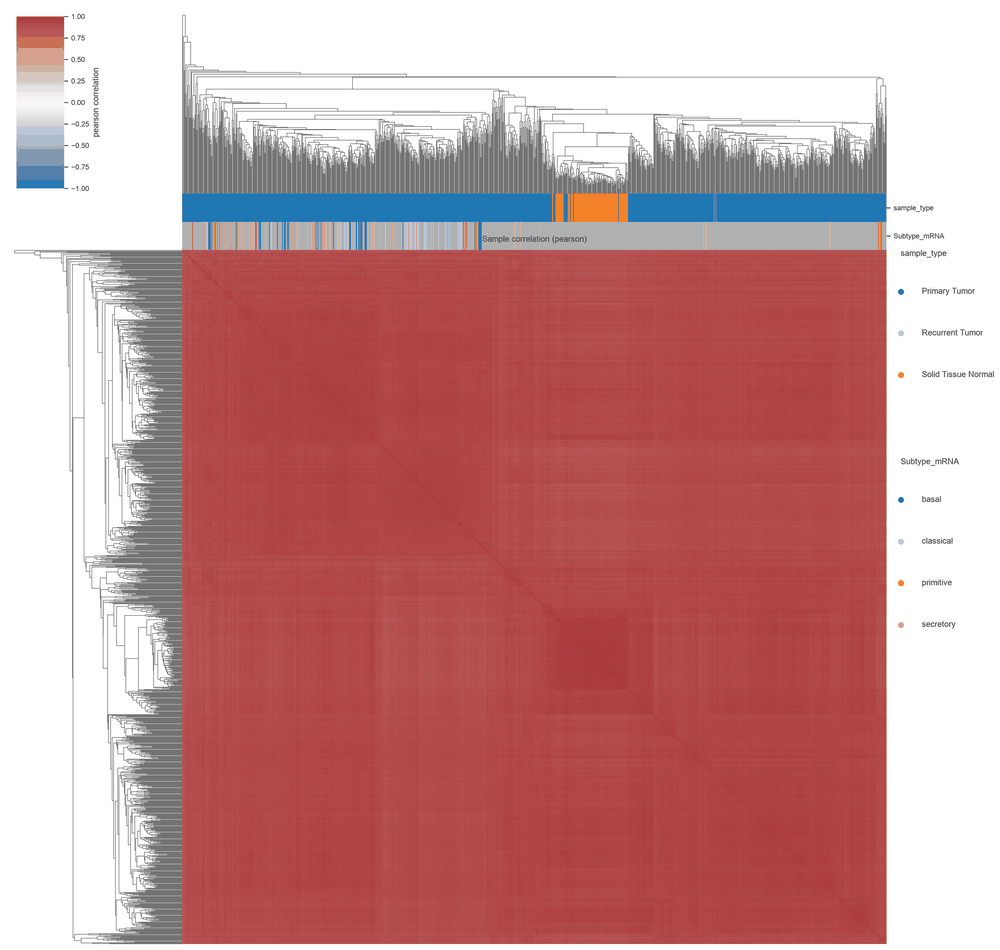

In [41]:
bk.pl.sample_correlation_clustergram(
    adata,
    layer="log1p_cpm",
    method="pearson",
    col_colors=["sample_type", "Subtype_mRNA"],
    show_labels=False,
    save=FIGURES + "sample_corr_clustergram.png",
)

C) Spearman correlation version (robust)

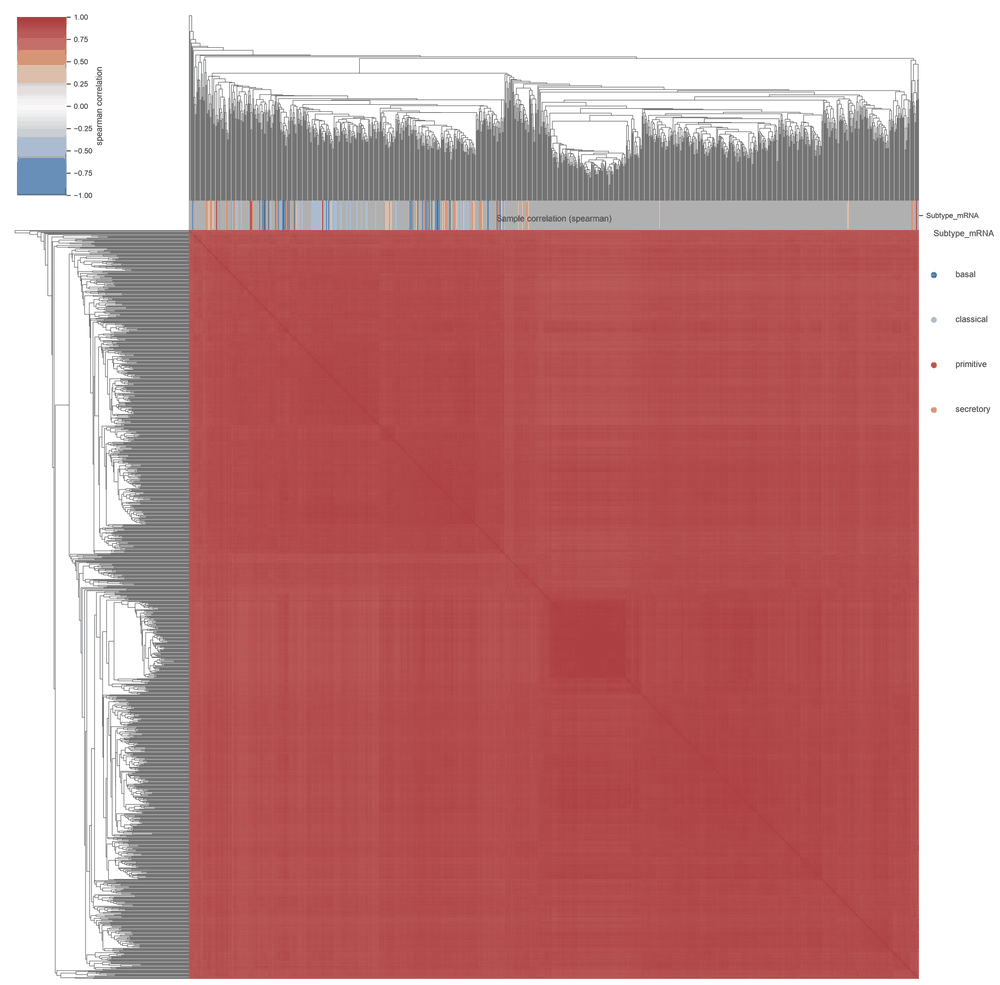

In [42]:
bk.pl.sample_correlation_clustergram(
    adata,
    layer="log1p_cpm",
    method="spearman",
    col_colors=["Subtype_mRNA"],
    save=FIGURES + "sample_corr_spearman.png",
)

## 7.6. Oncoprint

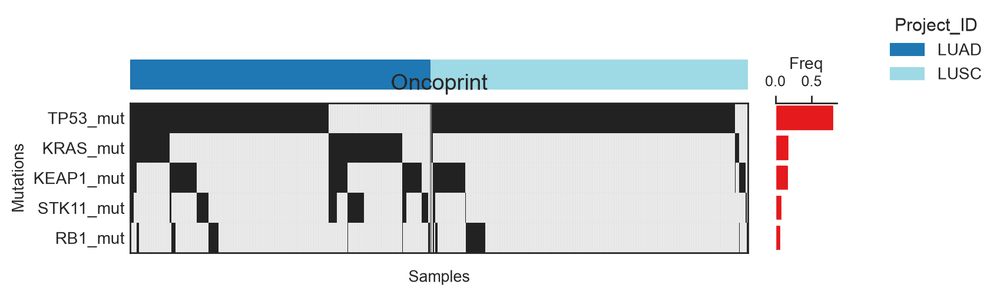

(<Figure size 2000x400 with 3 Axes>,
 <Axes: title={'center': 'Oncoprint'}, xlabel='Samples', ylabel='Mutations'>)

In [45]:
bk.pl.oncoprint(
    adata,
    mut_cols=["KRAS_mut", "TP53_mut", "RB1_mut", "STK11_mut", "KEAP1_mut"],
    groupby="Project_ID",
    group_blocks=True,
    grid_color="0.9",
    title=None,
    fontsize=12,
    figsize=(10,2),
    save=FIGURES + "oncoprint_mutfirst_by_project.png",
)

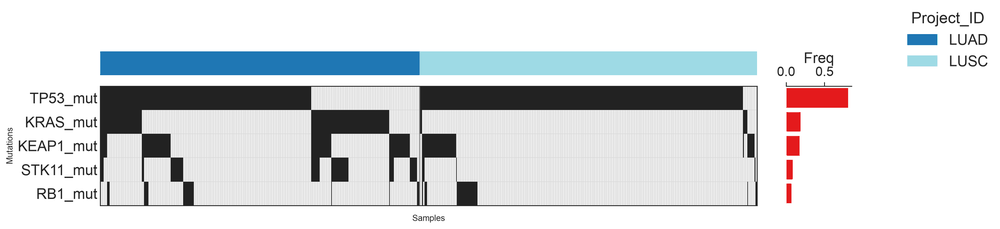

(<Figure size 4000x600 with 3 Axes>,
 <Axes: title={'center': ' '}, xlabel='Samples', ylabel='Mutations'>)

In [46]:
bk.pl.oncoprint(
    adata,
    mut_cols=["KRAS_mut", "TP53_mut", "RB1_mut", "STK11_mut", "KEAP1_mut"],
    groupby="Project_ID",
    group_blocks=True,
    fontsize=20,
    title=" ",
    figsize=(20,3),
    save=  FIGURES + "oncoprint_mutfirst_by_project_lung.png",
)

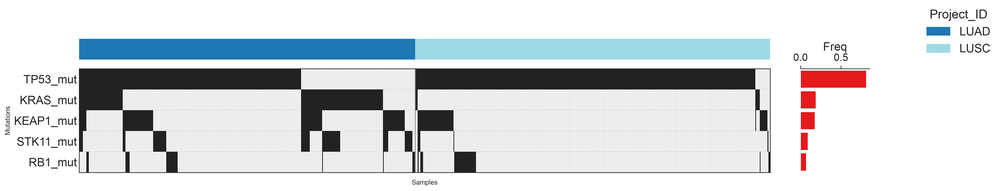

(<Figure size 5324x660 with 3 Axes>,
 <Axes: title={'center': ' '}, xlabel='Samples', ylabel='Mutations'>)

In [47]:
# Large datasets (avoid huge images)
bk.pl.oncoprint(
    adata,
    mut_cols=["KRAS_mut", "TP53_mut", "RB1_mut", "STK11_mut", "KEAP1_mut"],
    groupby="Project_ID",
    max_samples=800,          # IMPORTANT for TCGA-scale
    cell_size=0.03,           # compact columns
    fontsize=20,
    title=" ",
    save_dpi=300,             # keep under pixel limit
    save=FIGURES + "oncoprint_big.png",
)

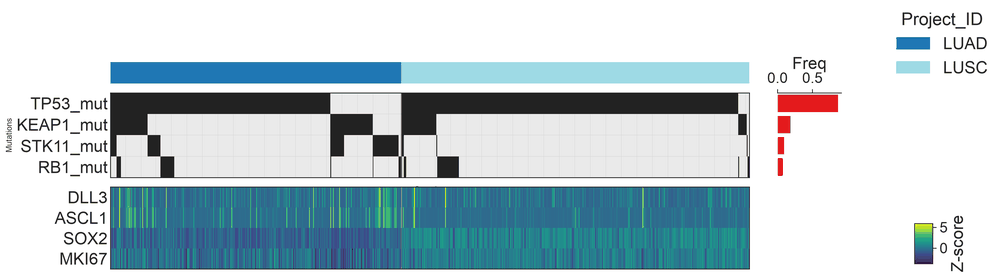

(<Figure size 4160x860 with 5 Axes>,
 <Axes: title={'center': ' '}, xlabel='Samples', ylabel='Mutations'>)

In [48]:
#Add expression tracks under the mutations
bk.pl.oncoprint(
    adata,
    mut_cols=["RB1_mut", "TP53_mut", "KEAP1_mut", "STK11_mut"],
    expr_genes=["DLL3", "ASCL1", "SOX2", "MKI67"],
    layer="log1p_cpm",
    expr_zscore=True,              # makes expression rows comparable
    groupby="Project_ID",
    sort_samples="pattern",
    #top_annotation_height=0.35,
    title=" ",
    fontsize=24,
    save_dpi=300,
    save=FIGURES + "oncoprint_plus_expr.png",
)

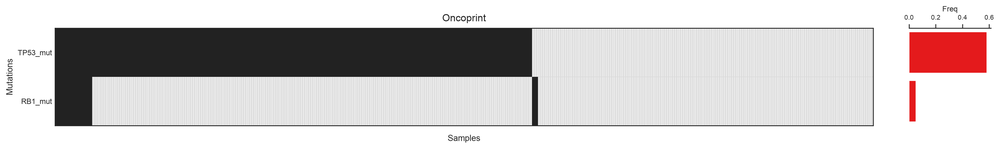

(<Figure size 4992x380 with 2 Axes>,
 <Axes: title={'center': 'Oncoprint'}, xlabel='Samples', ylabel='Mutations'>)

In [49]:
# Control the order
bk.pl.oncoprint(
    adata,
    drop_all_wt = False,
    mut_cols=["RB1_mut", "TP53_mut"],
    #group_order=,  # or any subset/order list(adata.obs_names),
    sort_samples="mut_first"     # "burden",     #"none",
)